Processing Well: Well-C

DataFrame Head:
    DEPTH       GR      RT      RHOB    NPHI     DTCO      DTSM     VCL  \
0  0.0000  80.4931  3.6572  2.506972  0.1822  77.0173  135.4693  0.4973   
1  0.1524  78.0726  3.7537  2.500166  0.1793  76.7501  134.5028  0.4887   
2  0.3048  72.0069  3.9638  2.501401  0.1734  76.2753  133.7607  0.5087   
3  0.4572  64.7344  4.1174  2.510778  0.1658  75.5534  133.0303  0.4904   
4  0.6096  60.5339  4.1920  2.523252  0.1594  74.7942  132.4168  0.4951   

     PIGN  SUWI FACIES  
0  0.0001   0.0  Shale  
1  0.0001   0.0  Shale  
2  0.0001   0.0  Shale  
3  0.0001   0.0  Shale  
4  0.0001   0.0  Shale  
DTSM already exists in the DataFrame.
    DEPTH       GR      RT      RHOB    NPHI     DTCO      DTSM     VCL  \
0  0.0000  80.4931  3.6572  2.506972  0.1822  77.0173  135.4693  0.4973   
1  0.1524  78.0726  3.7537  2.500166  0.1793  76.7501  134.5028  0.4887   
2  0.3048  72.0069  3.9638  2.501401  0.1734  76.2753  133.7607  0.5087   
3  0.4572  64.7344  

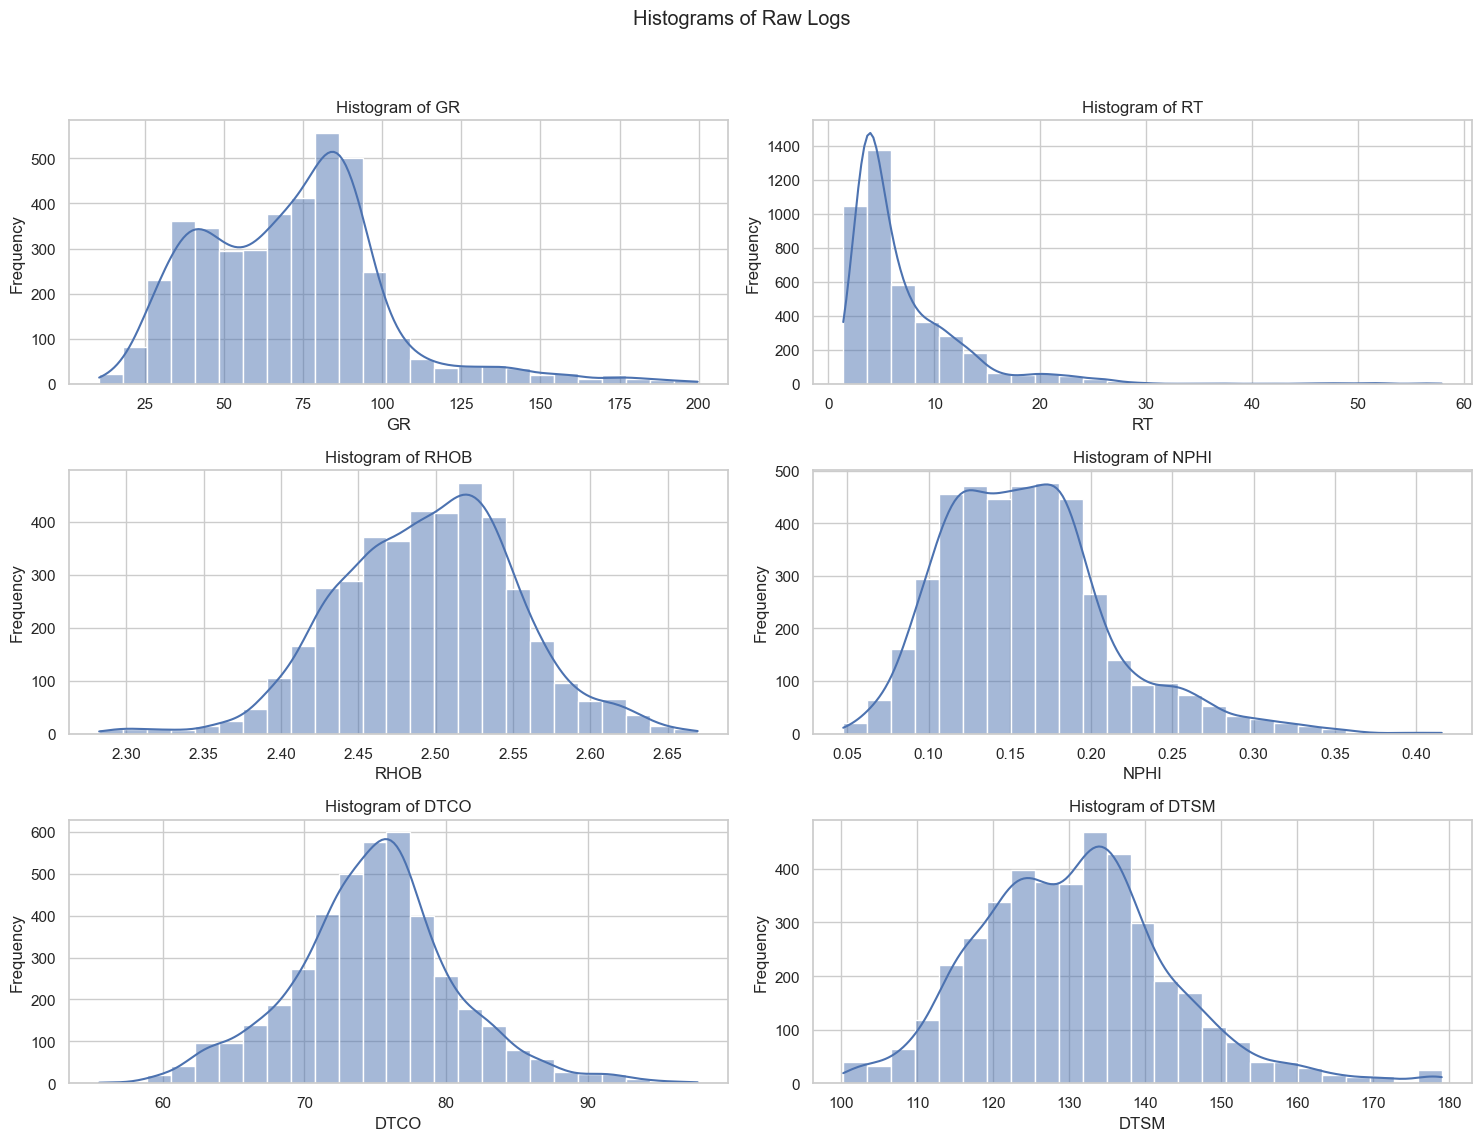

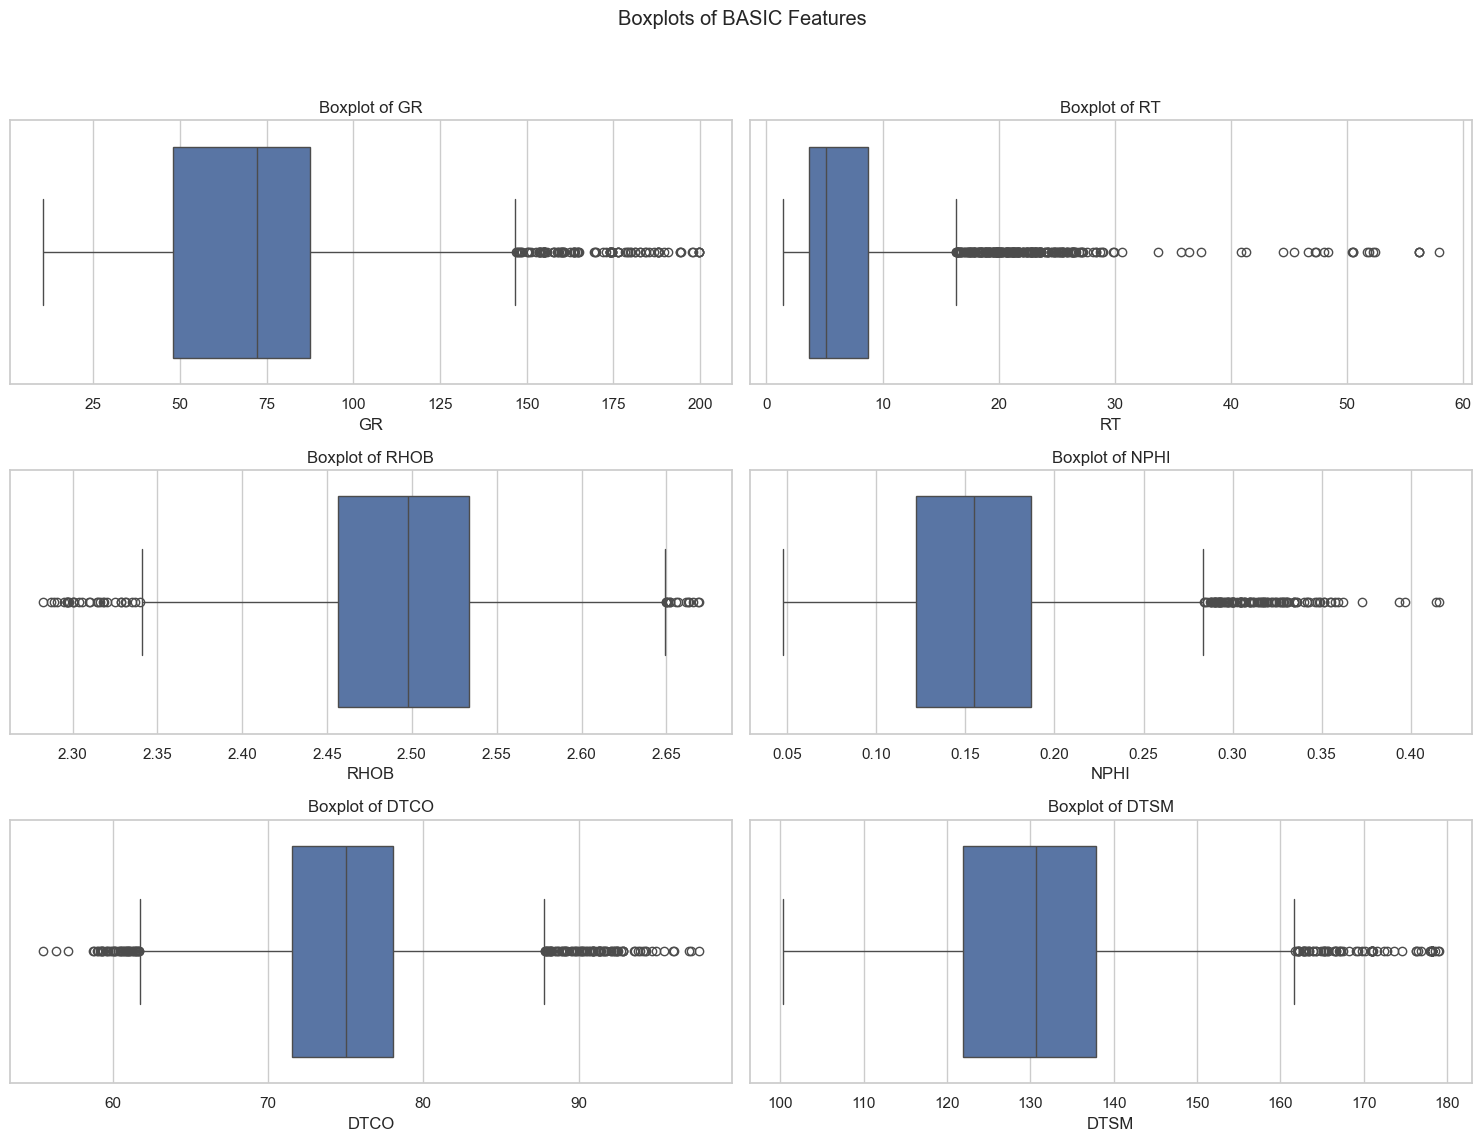

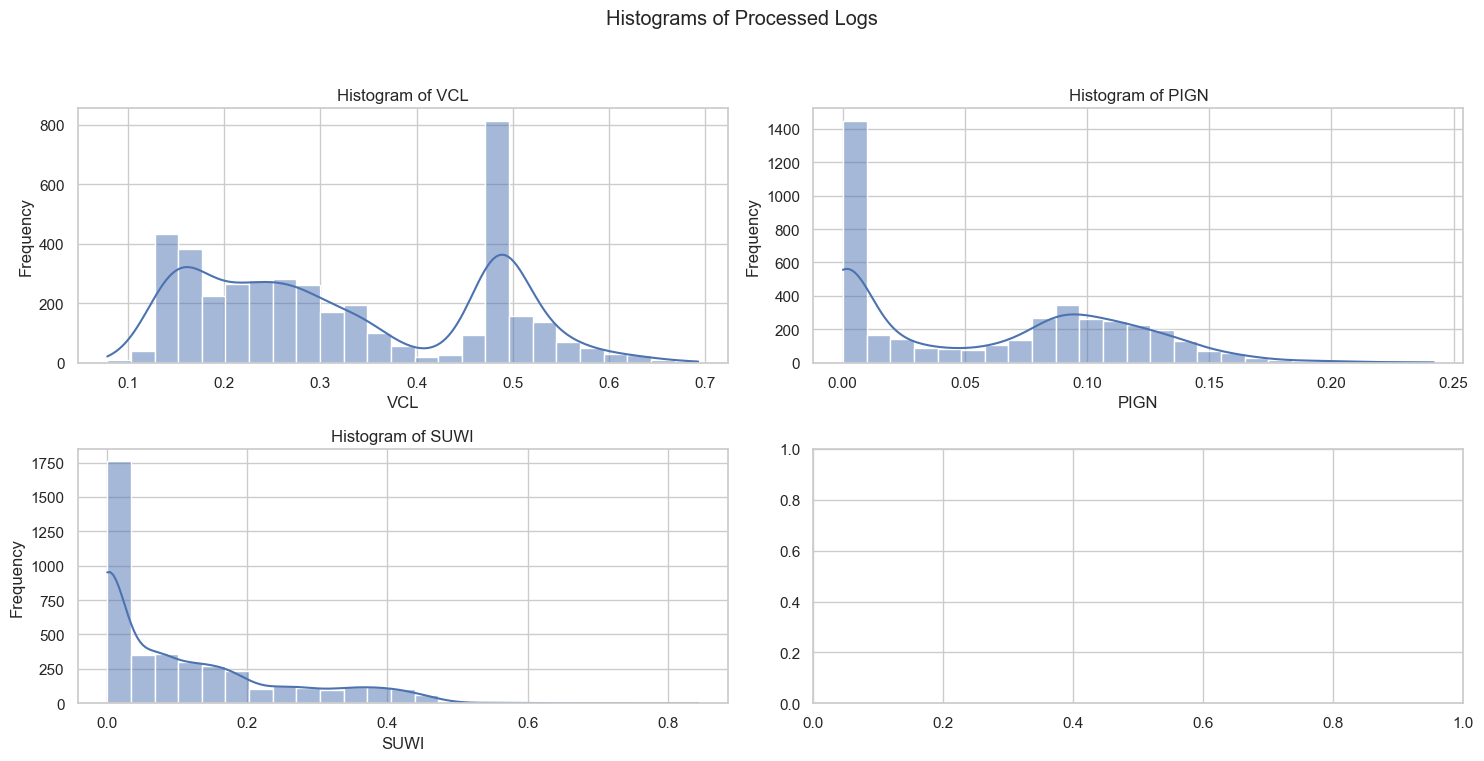

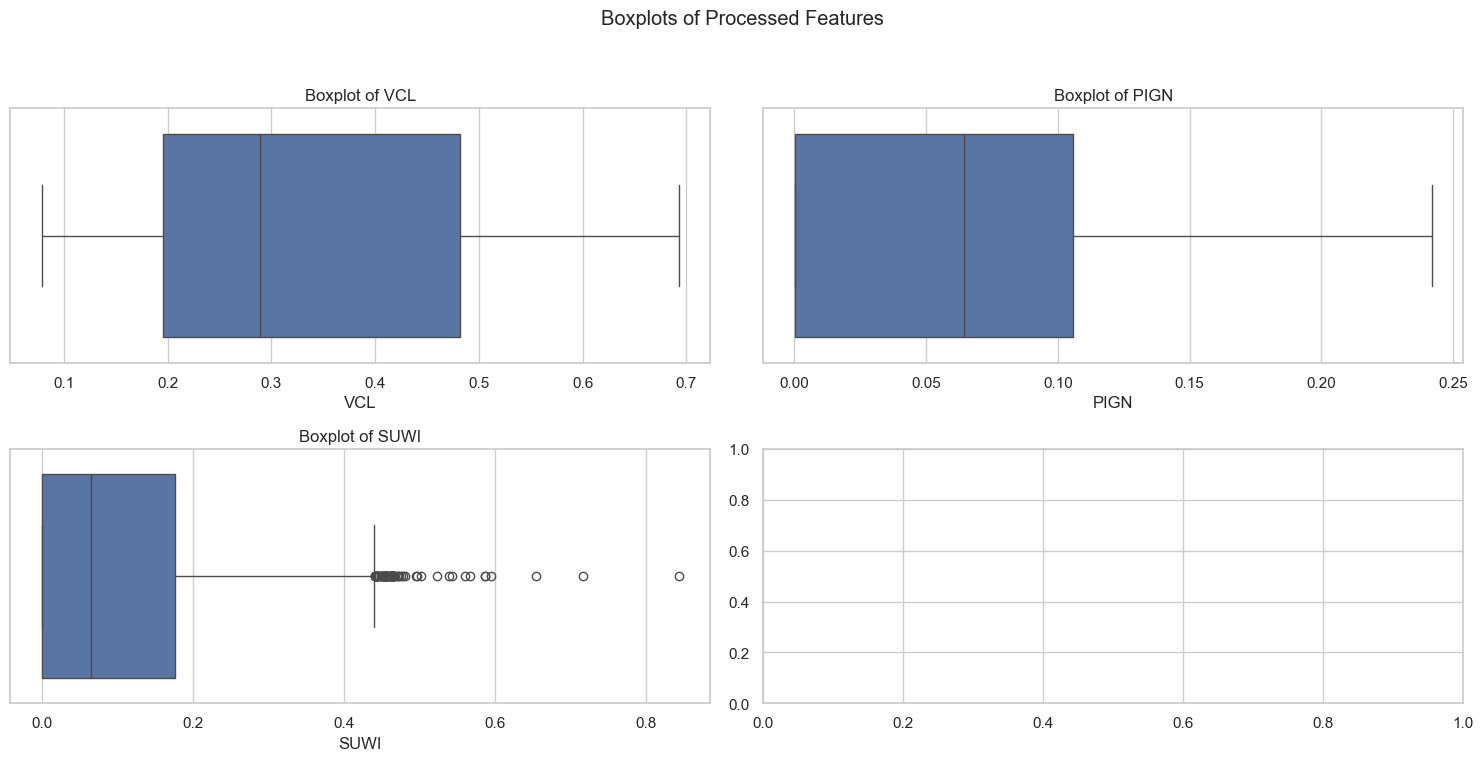

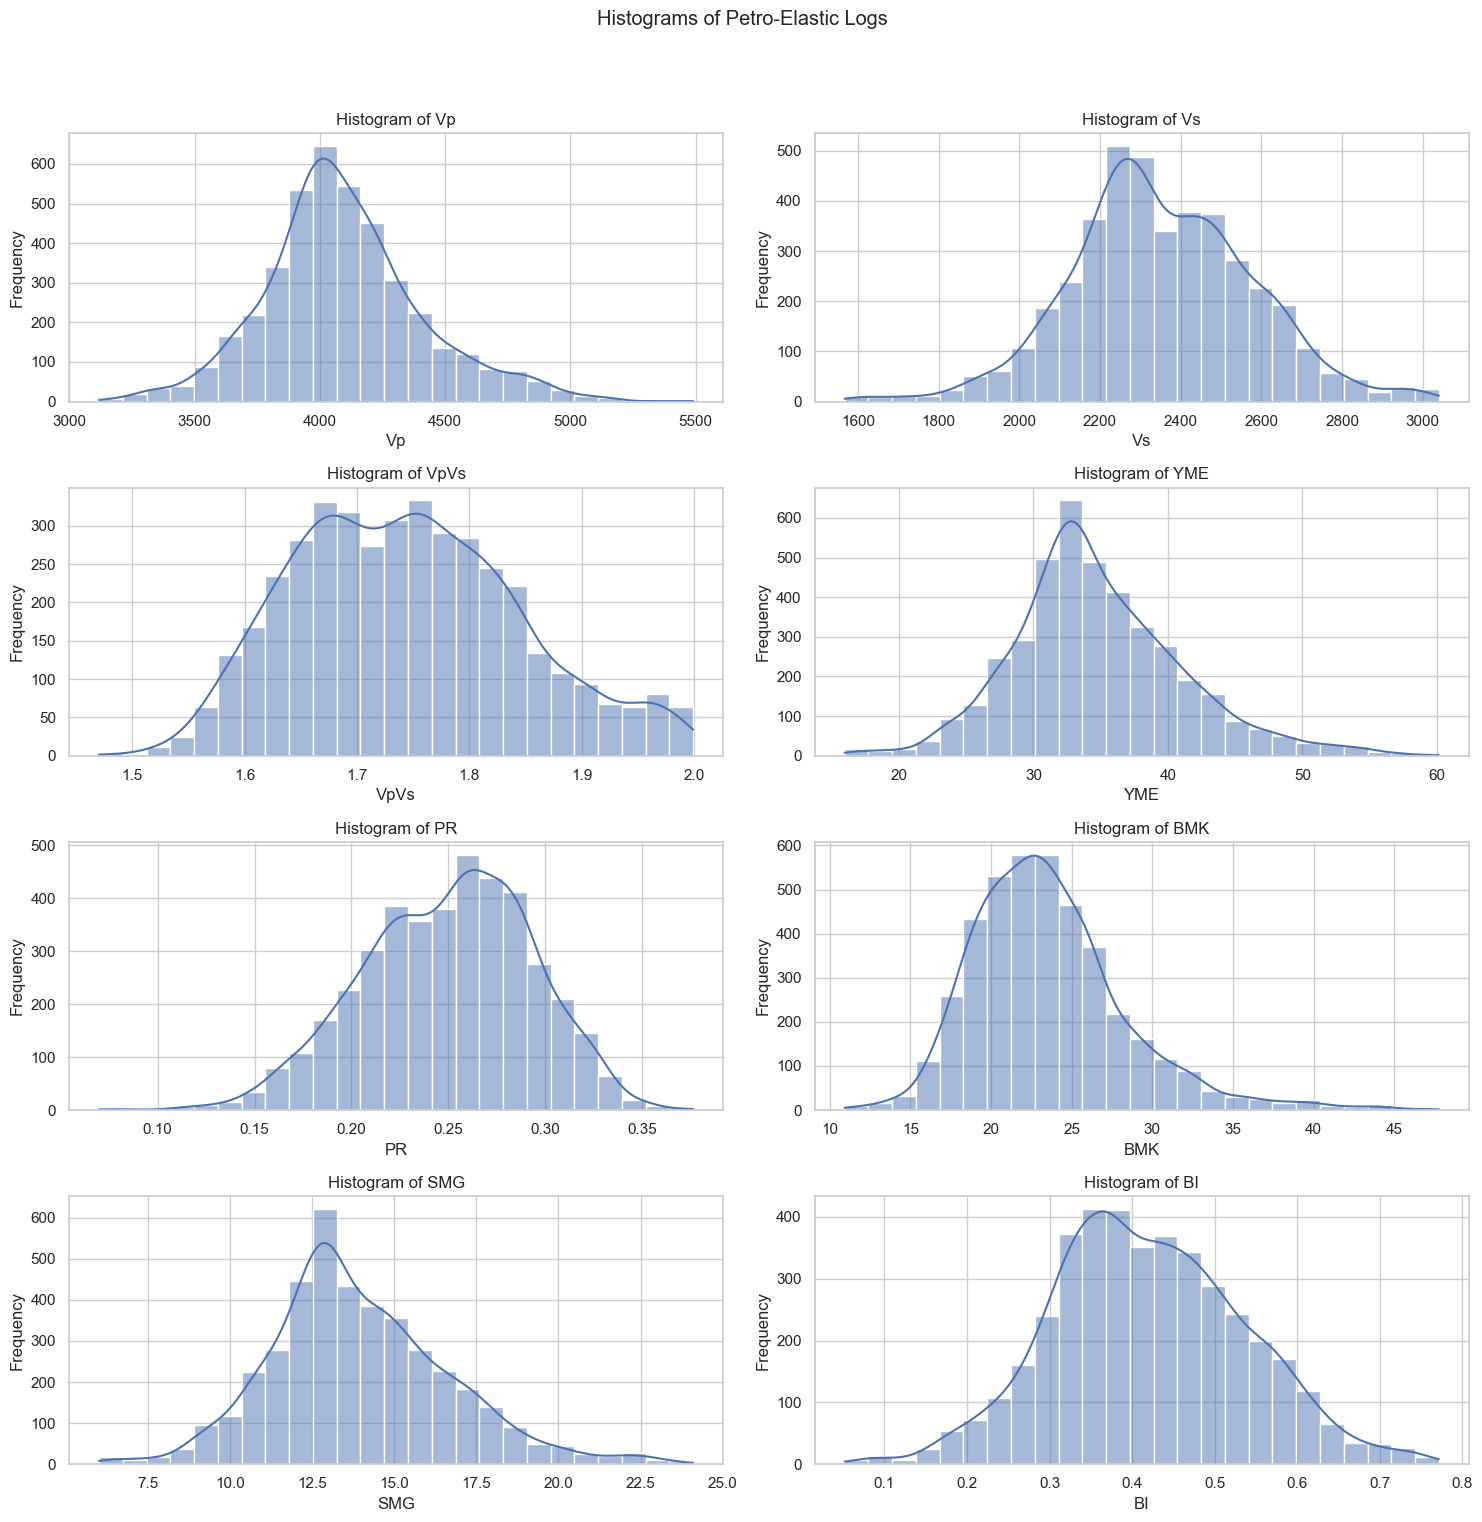

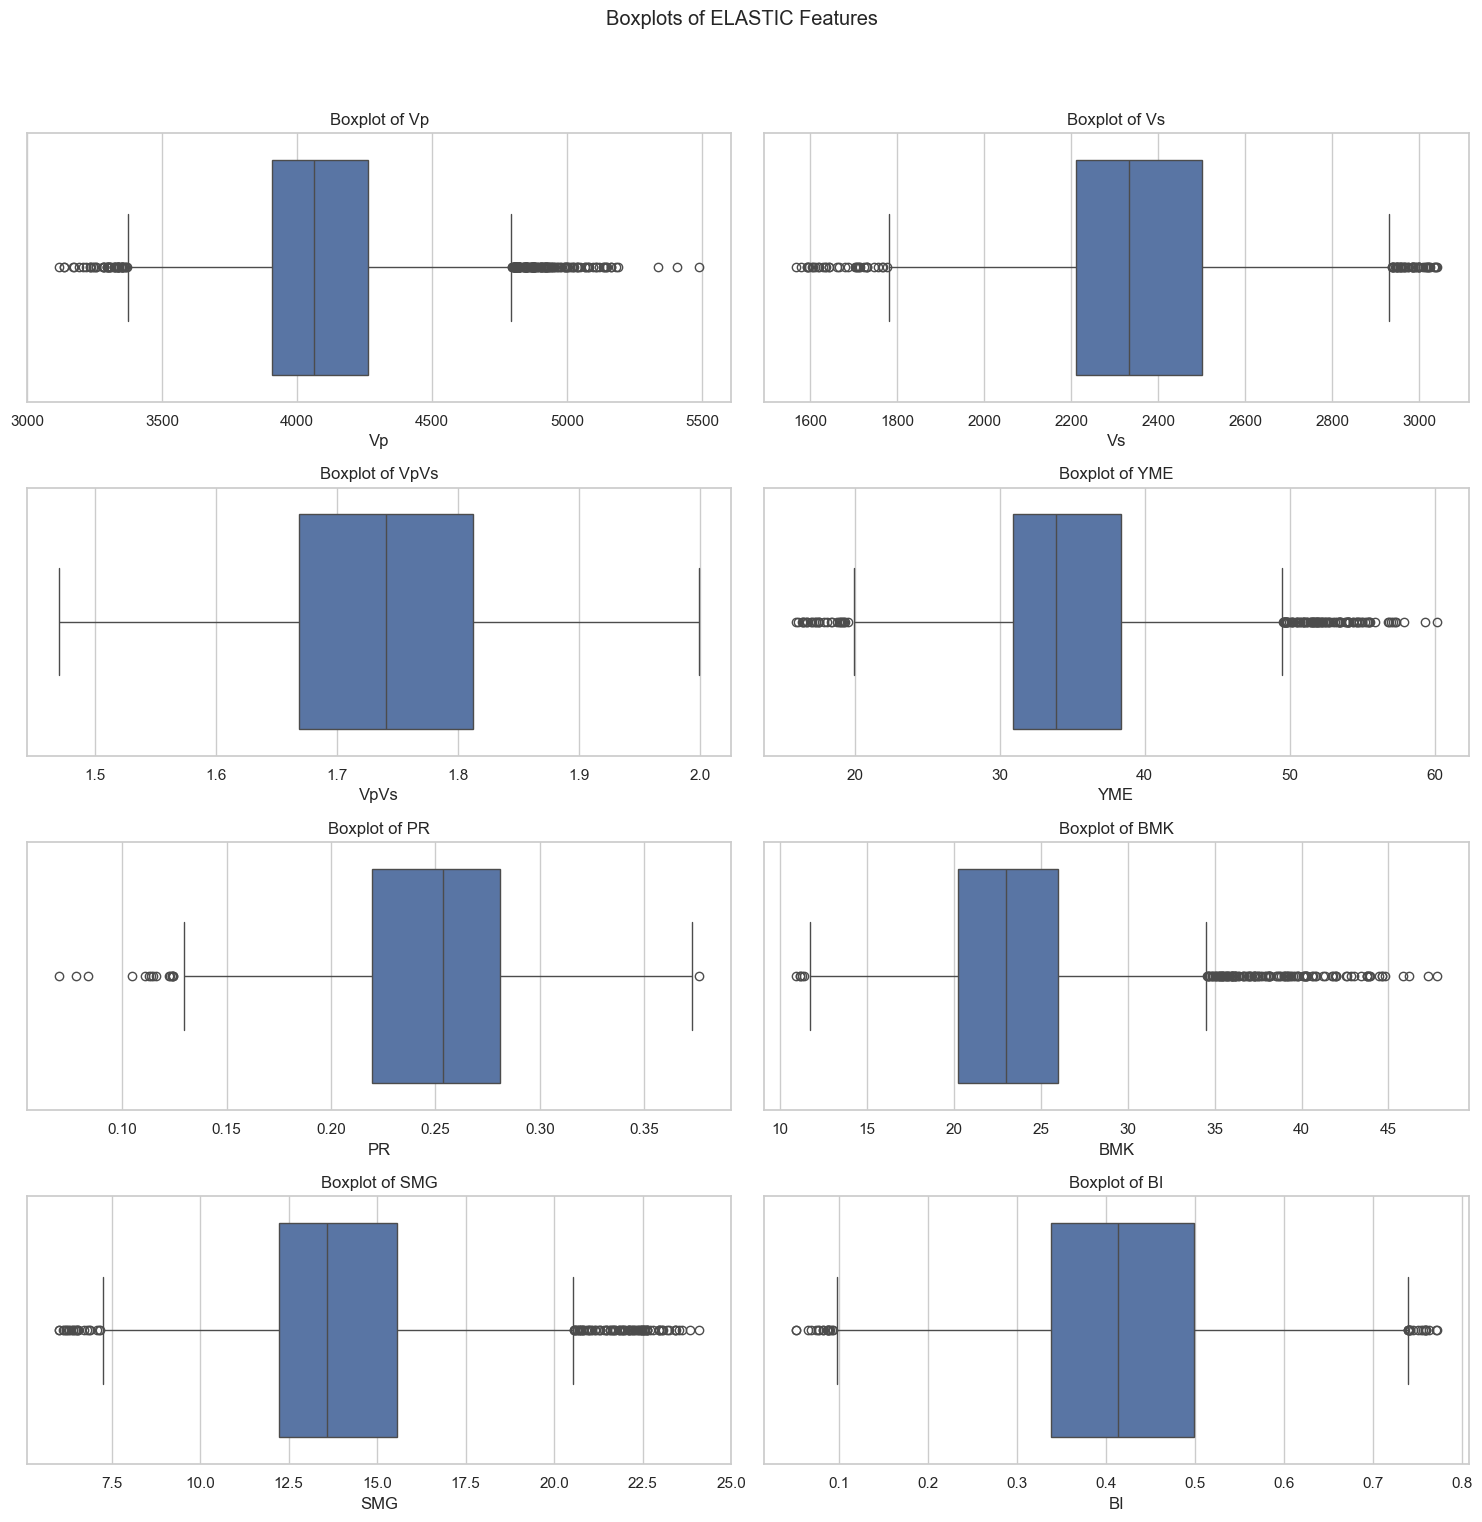

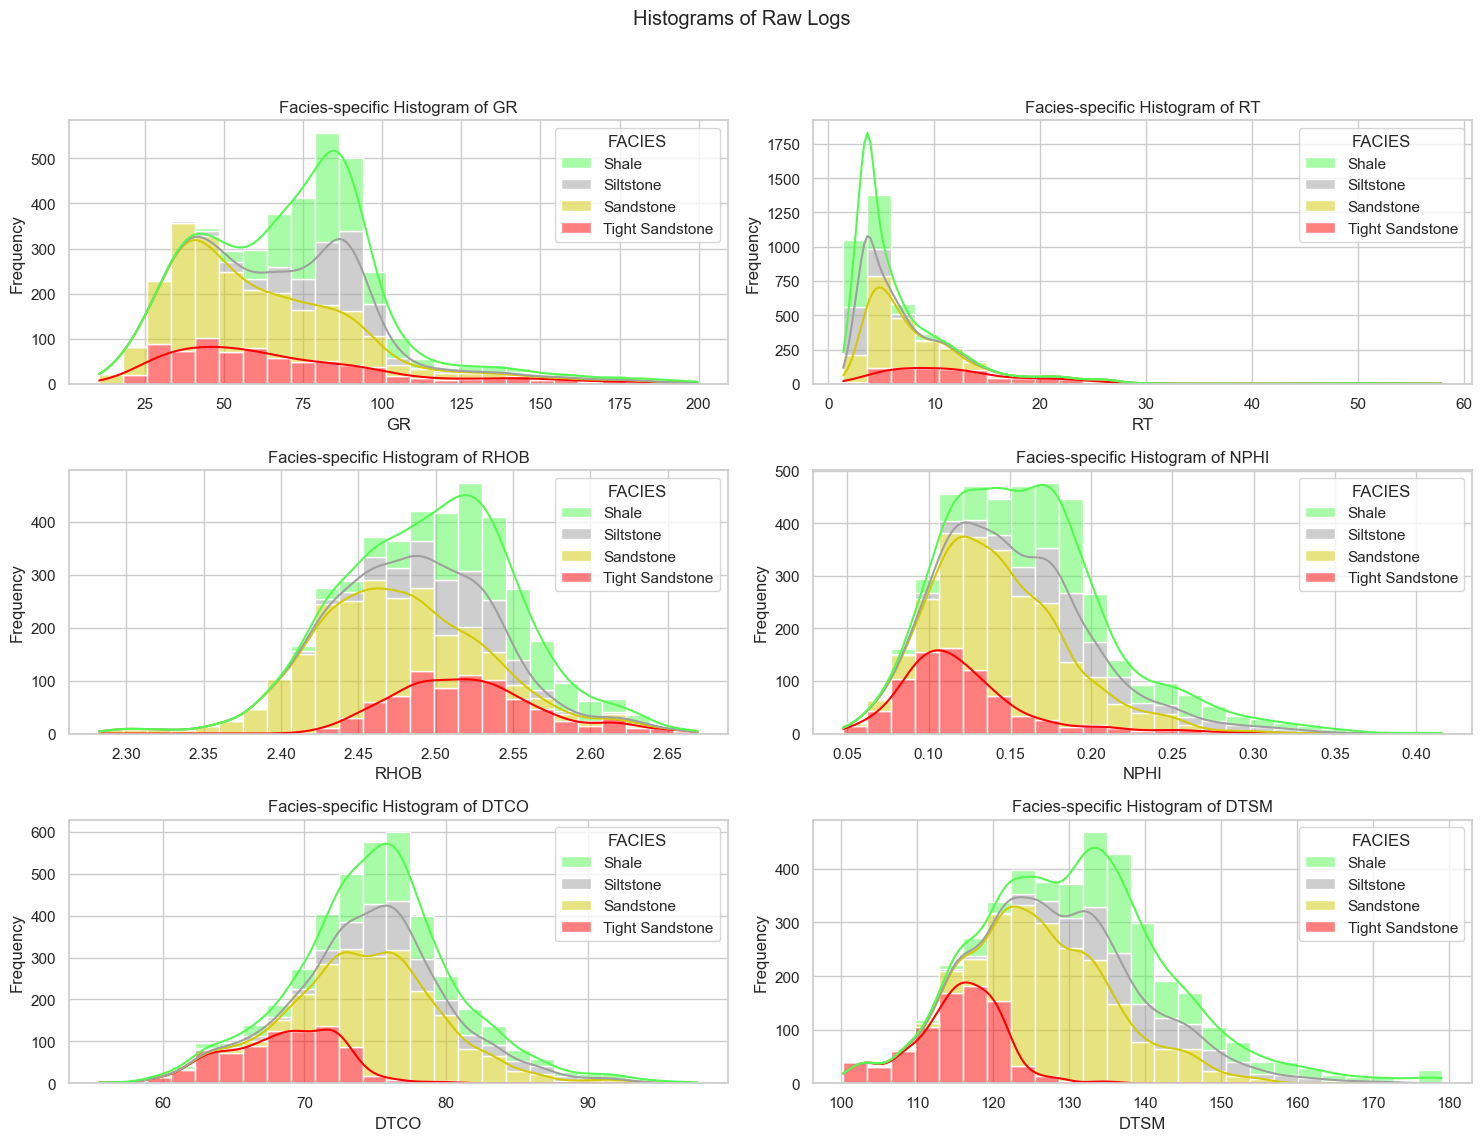

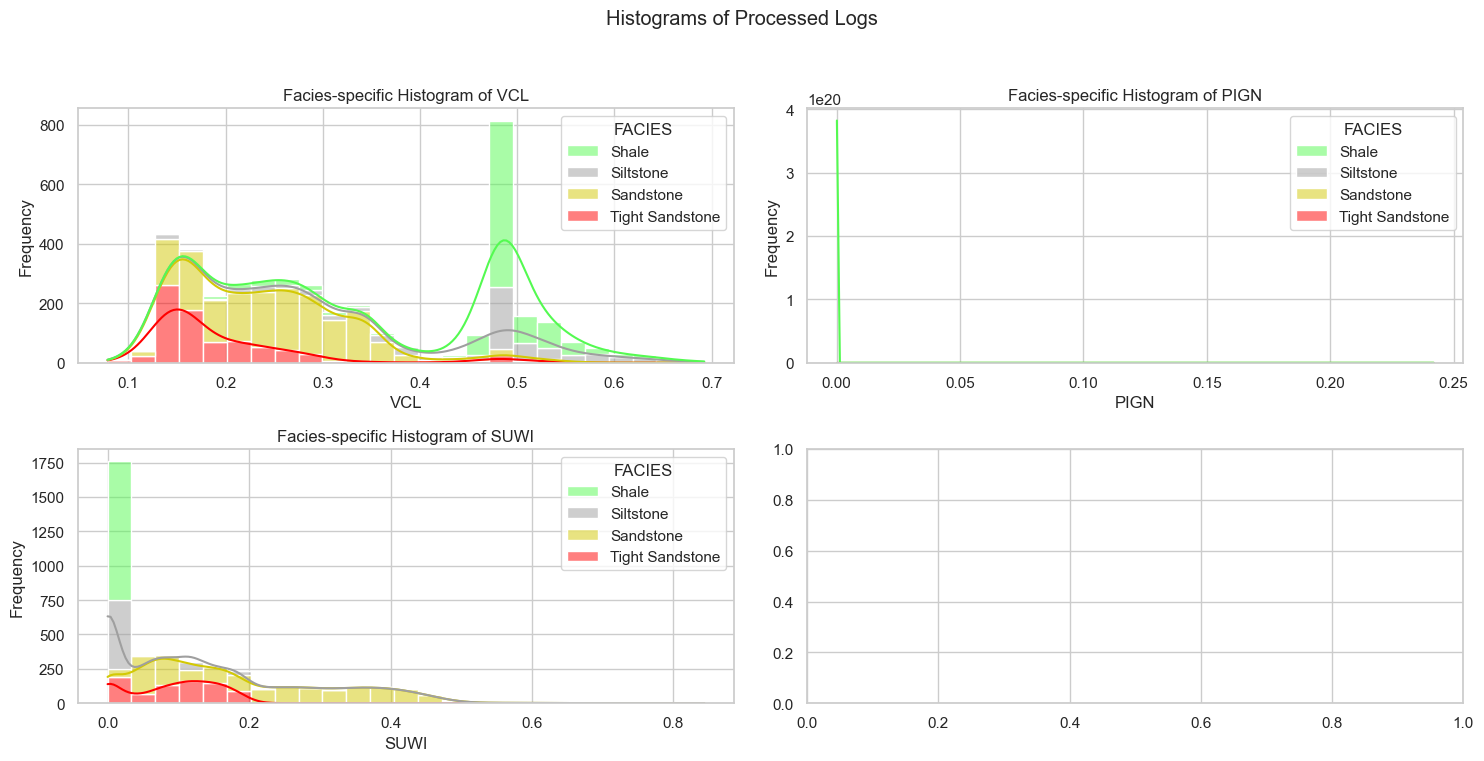

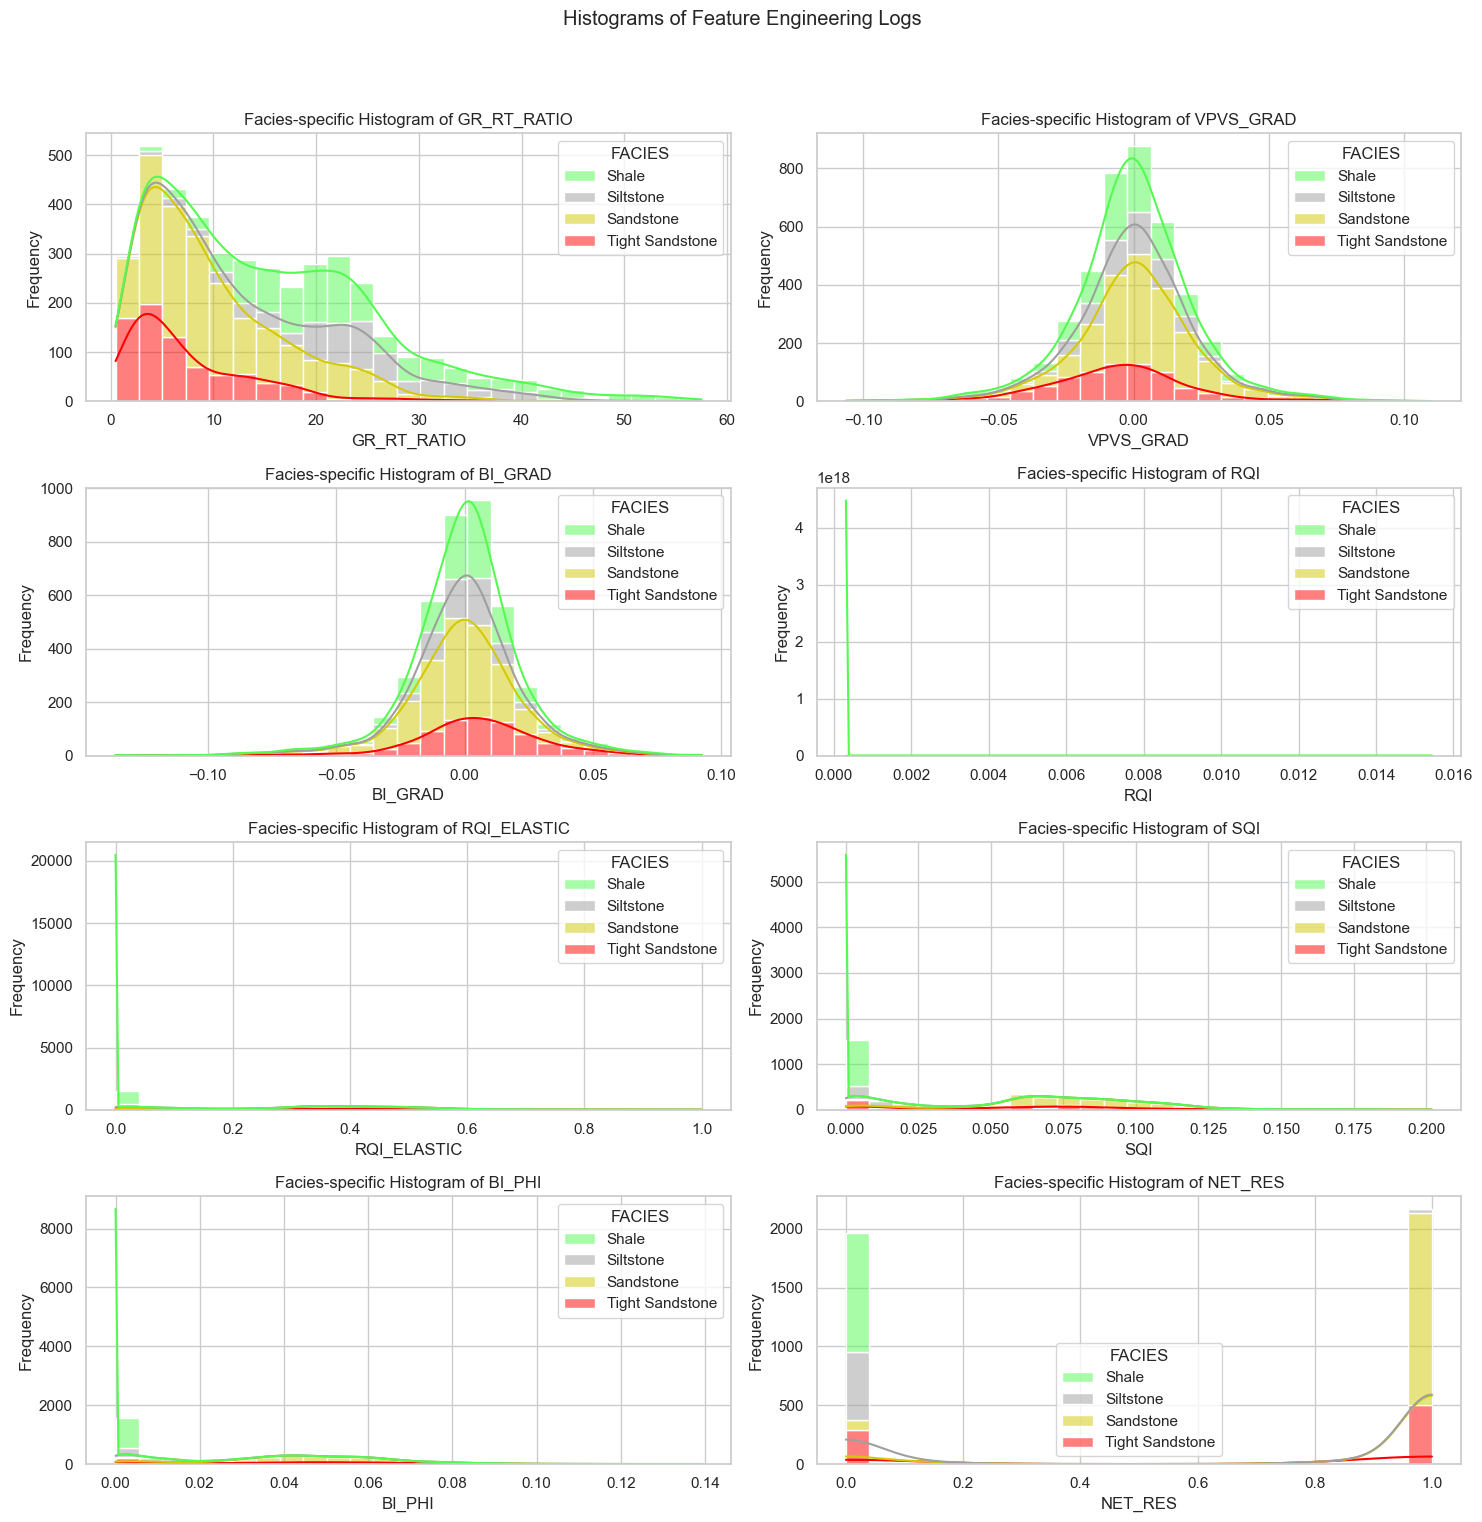

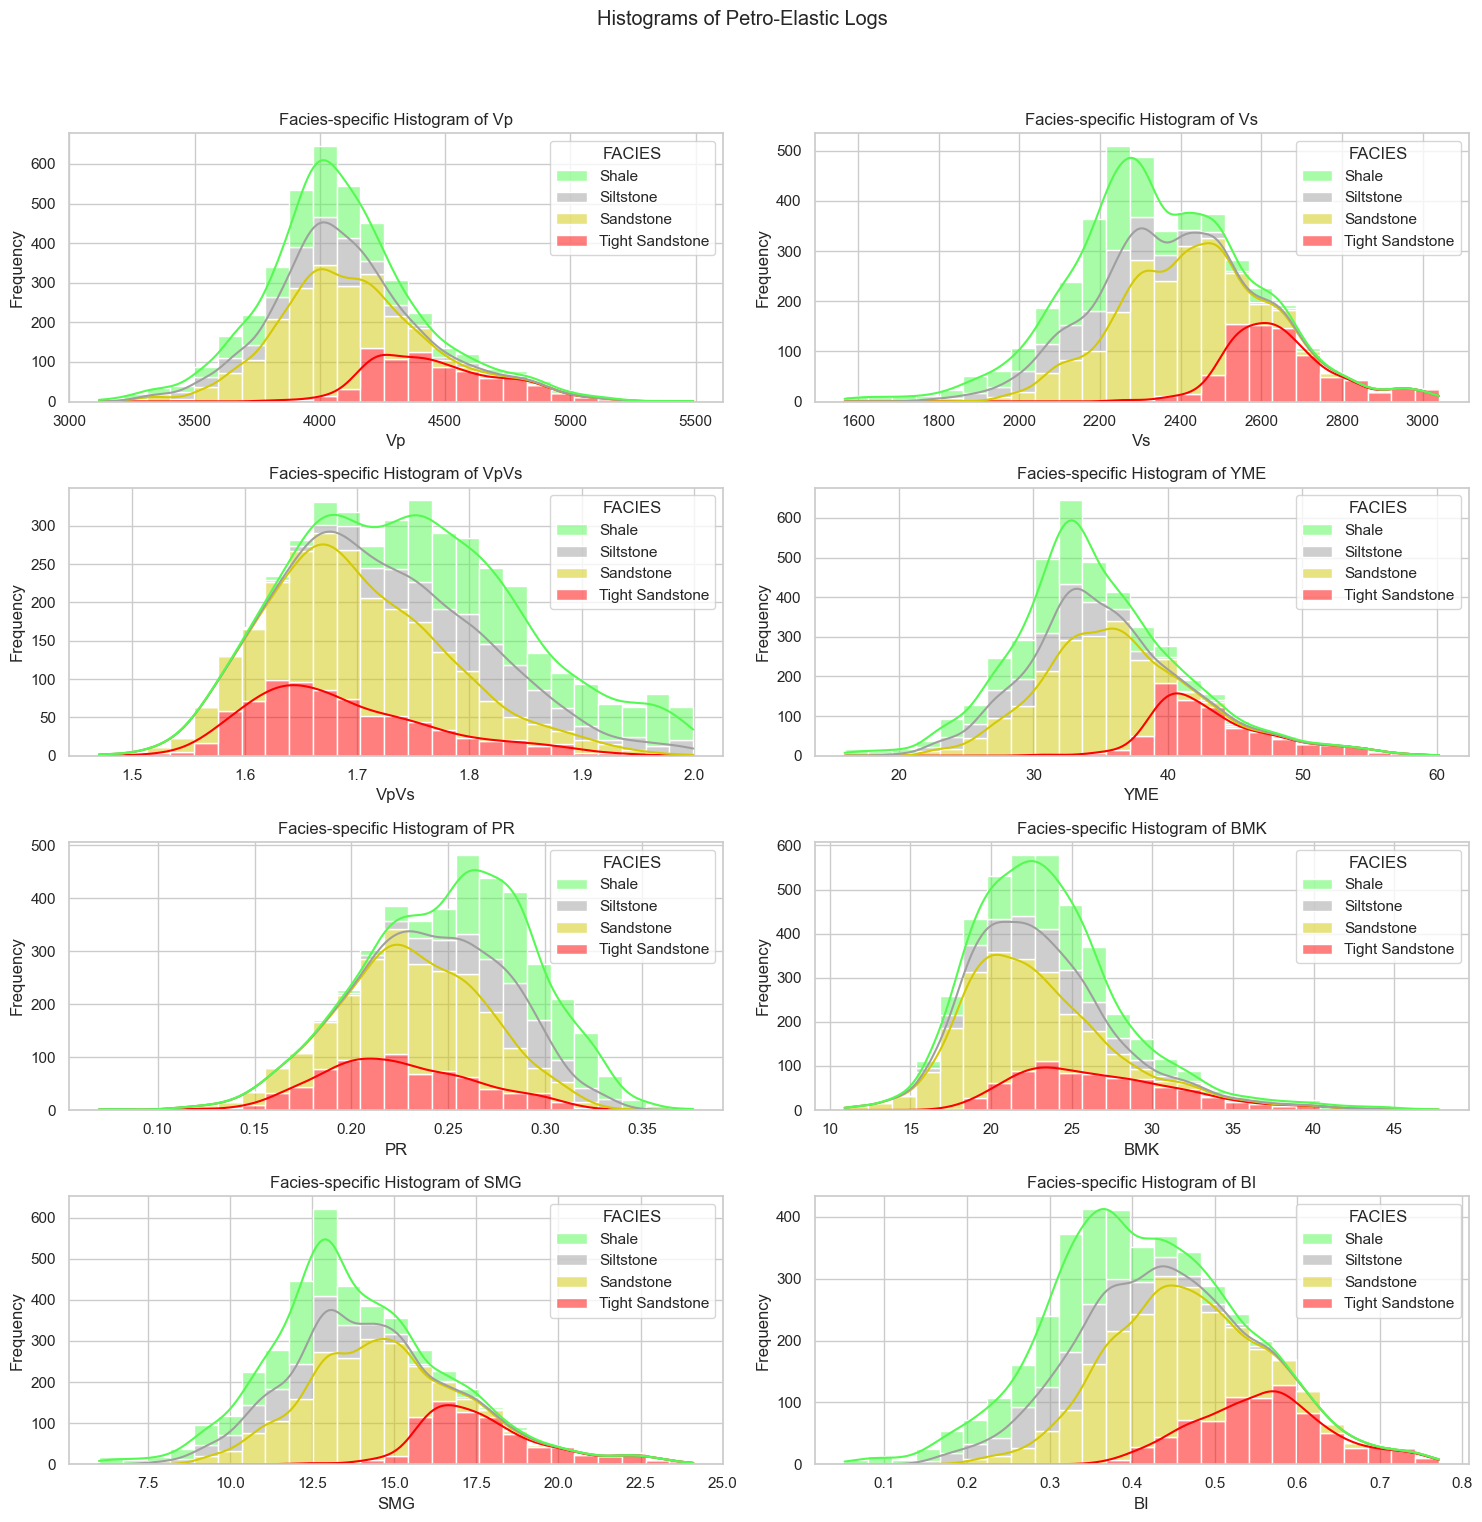

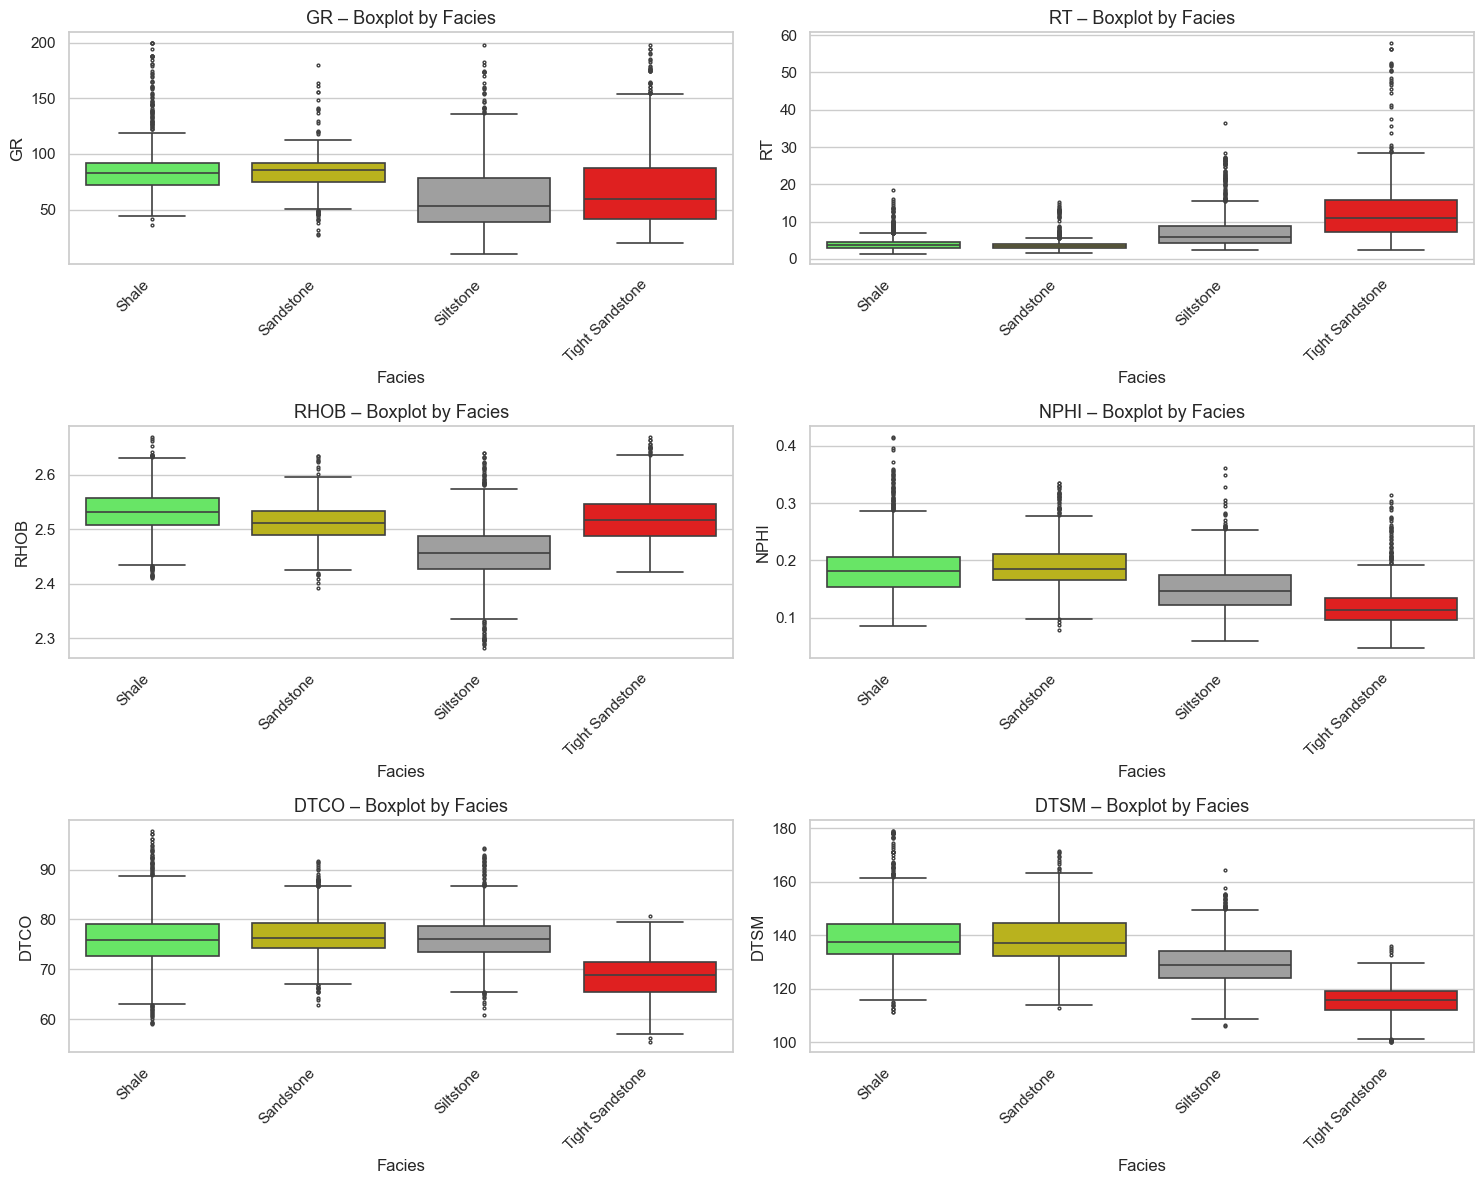

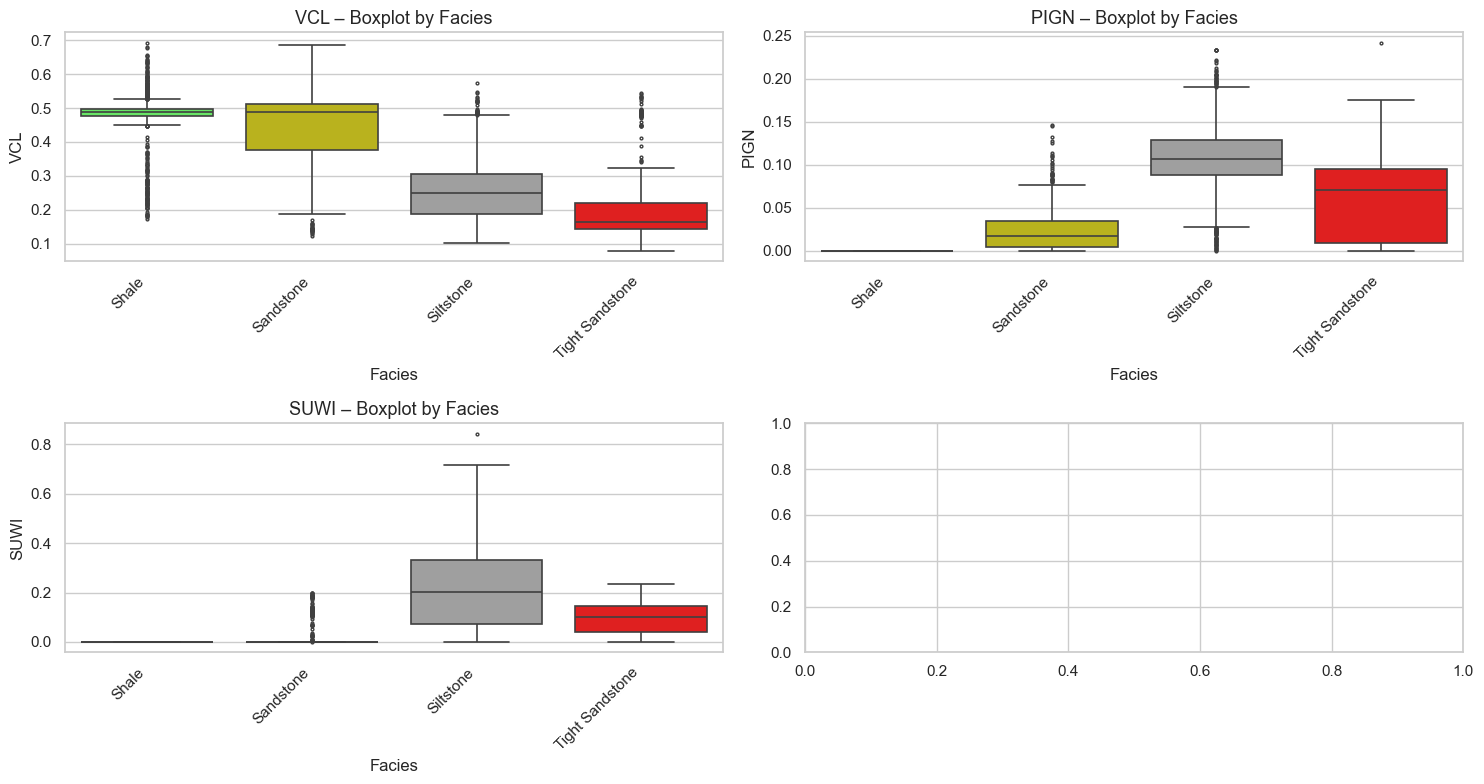

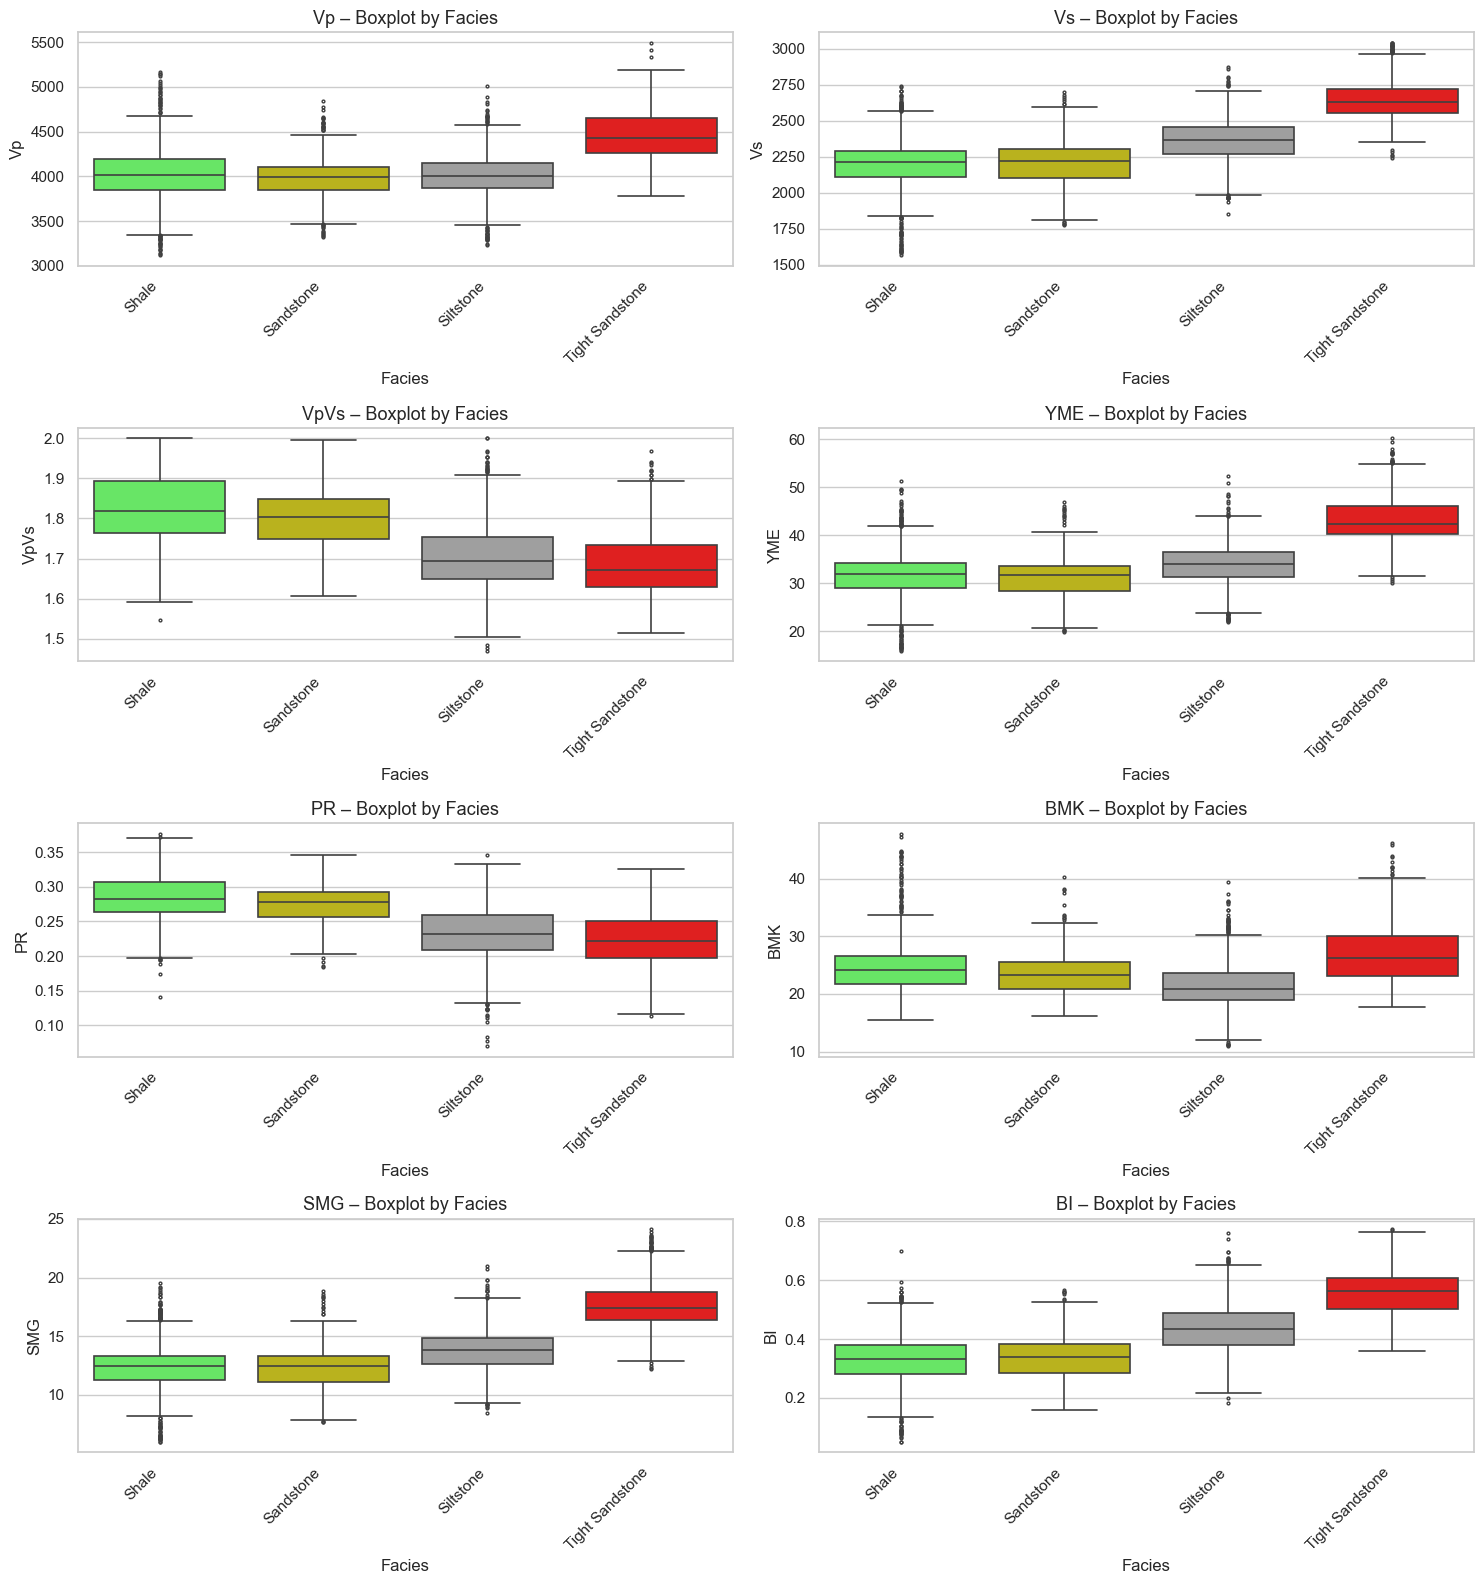

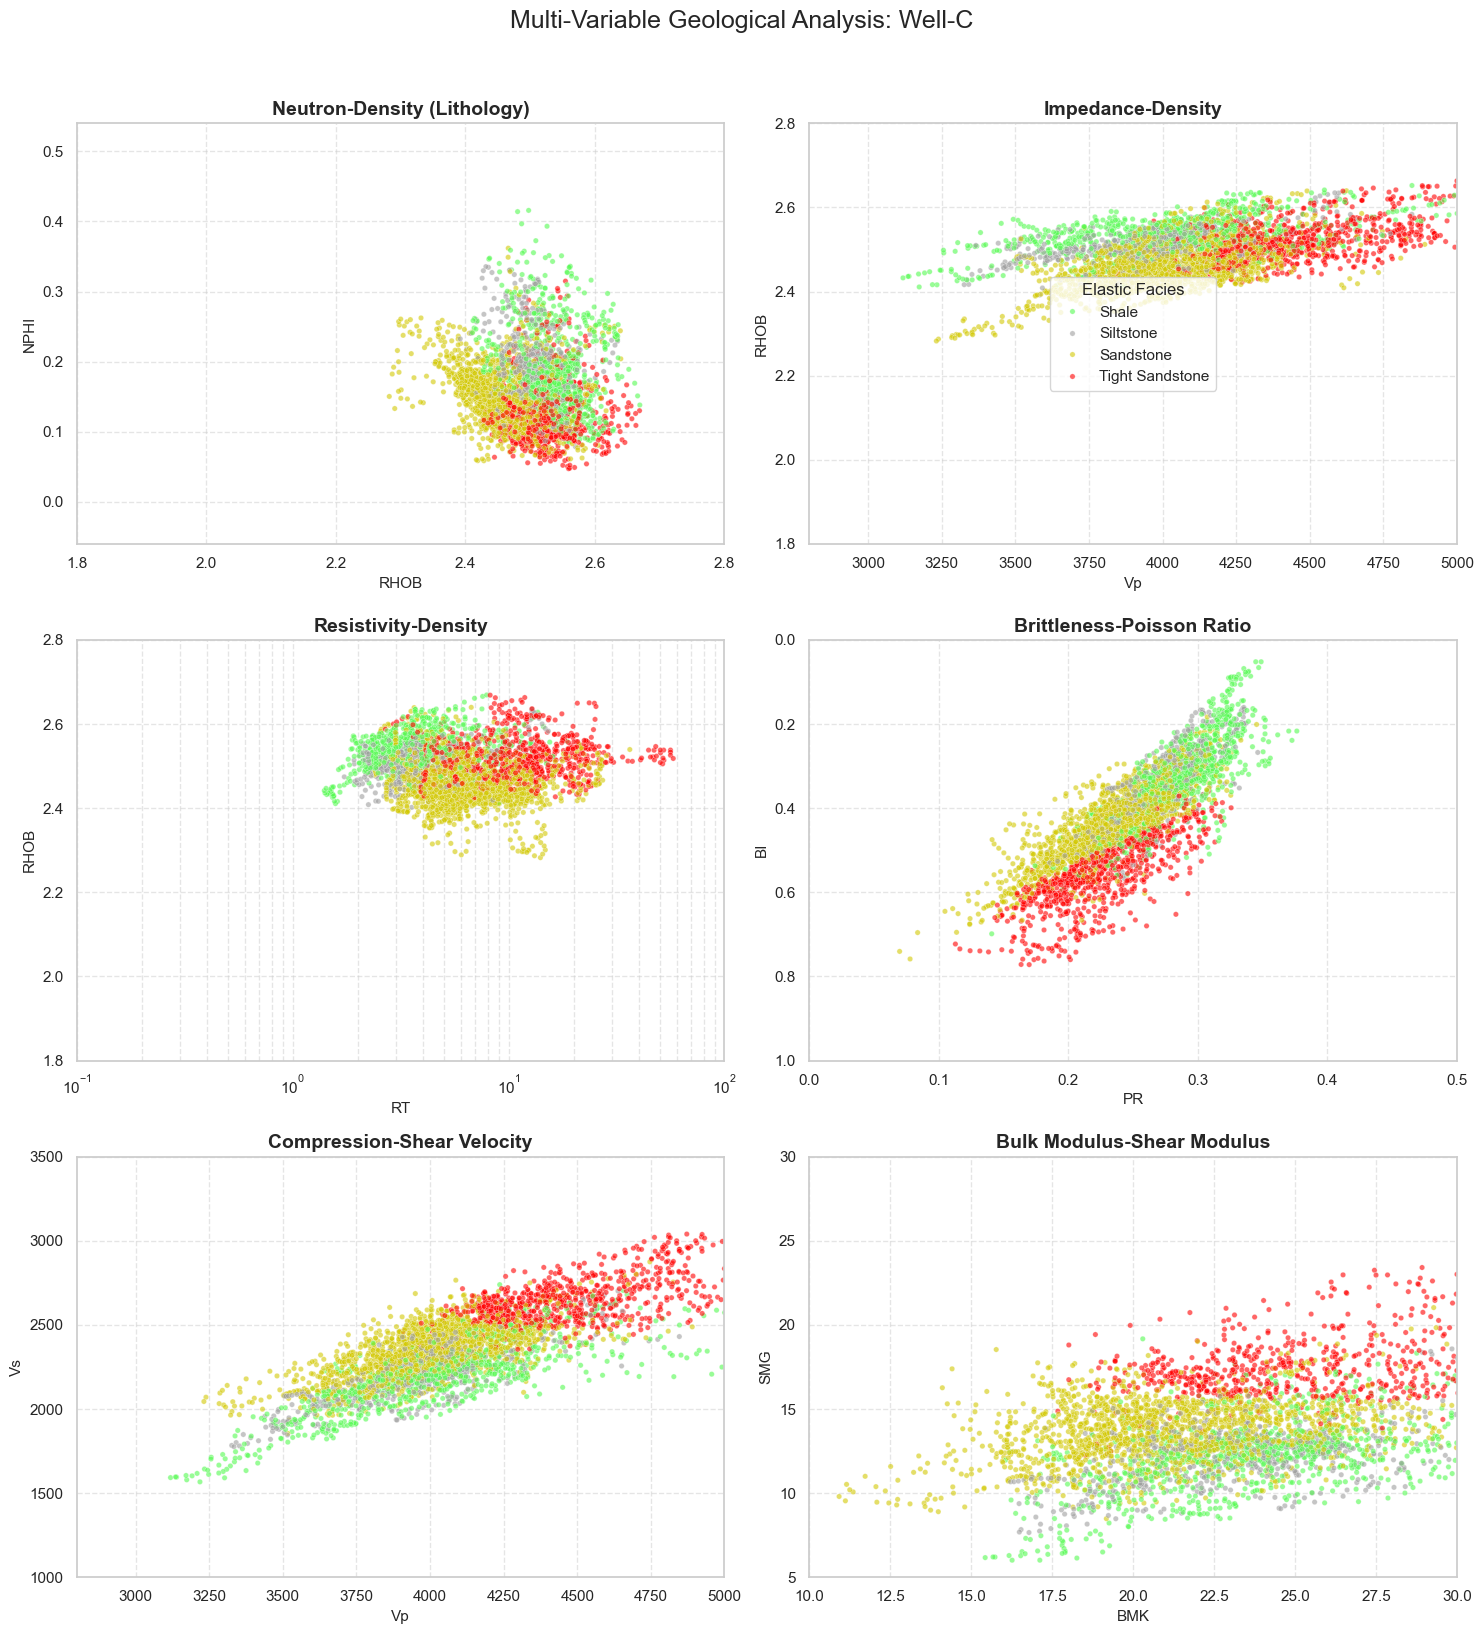

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import os # Added os for checking file existence, good practice

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

sns.set(style="whitegrid", context="notebook")
# --- Configuration ---
WELL_1_FILE = 'Well-C.csv' # Make sure this file exists in the current directory
# Split the string by the period (.) and select the first element [0]
WELL_1 = WELL_1_FILE.split('.')[0]
print(f"Processing Well: {WELL_1}")
# Check if the file exists before attempting to read
if not os.path.exists(WELL_1_FILE):
    print(f"Error: File '{WELL_1_FILE}' not found. Please check the path.")
else:
    # Read the CSV file
    df = pd.read_csv(WELL_1_FILE)
    # Display the first few rows
    print("\nDataFrame Head:")
    print(df.head())
# --- Compute Vp and Vs !
df = df.copy()
# Check if 'DTSM' exists; if not, compute it
if 'DTSM' not in df.columns:
    # Vp (Compressional Velocity) from DTCO (Compressional Slowness, us/ft)
    # Note: 304800 is the conversion factor for us/ft to m/s
    df["Vp"] = 304800.0 / df["DTCO"]
    
    # Vs (Shear Velocity) using an empirical linear correlation (Castagna's-type)
    df["Vs"] = (0.862 * (df["Vp"] / 1000) - 1.172) * 1000
    
    # DTSM = (Shear Slowness, us/ft) from Vs (Shear Velocity, m/s = 304800 / Vs)
    df["DTSM"] = 304800.0 / df["Vs"]
else:
    print("DTSM already exists in the DataFrame.")
    df["Vs"] = 304800.0 / df["DTSM"]

    
df.head()
def compute_elastic_parameters(df, dtco="DTCO", dtsm="DTSM", rhob="RHOB"):
    """
    Computes key elastic parameters (Moduli, Ratios, Impedance) from slowness (DTCO, DTSM) and density (RHOB) well logs.
    NOTE: The constant 304800 is the conversion factor for Slowness (us/ft) to Velocity (m/s).
    """
    # -------------------------------------------------
    # Ensure numeric types
    # -------------------------------------------------
    df_out = df.copy()
    required_cols = [dtco, dtsm, rhob]

    for col in required_cols:
        if col not in df_out.columns:
            raise ValueError(f"Missing required column: {col}")
        df_out[col] = pd.to_numeric(
            df_out[col],
            errors="coerce"
        )

    # -------------------------------------------------
    # Replace invalid values with NaN
    # -------------------------------------------------
    df_out[dtco] = df_out[dtco].where(df_out[dtco] > 0)
    df_out[dtsm] = df_out[dtsm].where(df_out[dtsm] > 0)
    df_out[rhob] = df_out[rhob].where(df_out[rhob] > 0)

    # -------------------------------------------------
    # Velocity Calculation (m/s)
    # -------------------------------------------------
    df_out["Vp"] = 304800.0 / df_out[dtco]
    df_out["Vs"] = 304800.0 / df_out[dtsm]

    # -------------------------------------------------
    # Density Conversion (kg/m3)
    # -------------------------------------------------
    df_out["Rho"] = df_out[rhob] * 1000.0

    # -------------------------------------------------
    # Elastic Moduli
    # -------------------------------------------------
    # Shear Modulus (GPa)
    df_out["SMG"] = (df_out["Rho"] * (df_out["Vs"] ** 2)) / 1e9

    # Bulk Modulus (GPa)
    df_out["BMK"] = (df_out["Rho"] * ((df_out["Vp"] ** 2) - ((4.0 / 3.0) * (df_out["Vs"] ** 2)))) / 1e9

    # Young's Modulus
    denominator = (3 * df_out["BMK"] + df_out["SMG"])
    df_out["YME"] = np.where(denominator != 0, ( 9 * df_out["BMK"] * df_out["SMG"]) / denominator, np.nan)

    # Vp/Vs Ratio
    df_out["VpVs"] = np.where(df_out["Vs"] != 0, df_out["Vp"] / df_out["Vs"], np.nan)

    # Poisson's Ratio
    vp_vs_sq = df_out["VpVs"] ** 2
    denominator_pr = vp_vs_sq - 1
    df_out["PR"] = np.where(denominator_pr != 0, ((0.5 * vp_vs_sq) - 1) / denominator_pr, np.nan)

    # Acoustic Impedance
    df_out["AI"] = (df_out["Rho"] * df_out["Vp"]) / 1000

    # Shear Impedance
    df_out["SI"] = (df_out["Rho"] * df_out["Vs"]) / 1000

    # P-wave Modulus
    df_out["M"] = (df_out["Rho"] * (df_out["Vp"] ** 2)) / 1e9
    
    # Mu rho
    df_out["MU_RHO"] = df_out["RHOB"] * (df_out["Vs"]**2) / 1e6

    # Lambda rho
    df_out["LAMBDA_RHO"] = (df_out["RHOB"] * (df_out['Vp']**2 - 2*df_out['Vs']**2)) / 1e6


    return df_out

df = compute_elastic_parameters(df)
print(df.head())

def compute_brittleness(df):
    """
    Computes the Rickman Brittleness Index (BI_Rickman) using normalized
    Young's Modulus (BI_E) and normalized Poisson's Ratio (BI_NU).
    """
   
    df = df.copy()

    # --- 1. Determine Min/Max for Normalization ---
    E_min, E_max = df["YME"].min(), df["YME"].max()
    nu_min, nu_max = df["PR"].min(), df["PR"].max()
    
    # --- 2. Normalize Young's Modulus (BI_E) ---
    # BI_E = (E - E_min) / (E_max - E_min). Higher is more brittle.
    E_range = E_max - E_min
    if E_range != 0:
        df["BI_E"] = (df["YME"] - E_min) / E_range
    else:
        # Handle case where Youngs_Modulus is constant (set BI_E to 0 or NaN)
        df["BI_E"] = 0.0
    
    # --- 3. Normalize Poisson's Ratio (BI_NU) ---
    # BI_NU = (nu_max - nu) / (nu_max - nu_min). Lower nu is more brittle.
    nu_range = nu_max - nu_min
    if nu_range != 0:
        df["BI_NU"] = (nu_max - df["PR"]) / nu_range
    else:
        # Handle case where Poissons_Ratio is constant
        df["BI_NU"] = 0.0
    
    # --- 4. Calculate Rickman Brittleness Index ---
    # BI = 0.5 * (BI_E + BI_NU)
    df["BI"] = 0.5 * (df["BI_E"] + df["BI_NU"])
    
    # Ensure the index is physically constrained between 0 and 1
    df["BI"] = df["BI"].clip(0, 1)

    return df
df = compute_brittleness(df)

# ======================================================================
# --- 5. OUTLIER CLEANING ---
# ======================================================================
# Define Petrophysical Bounds for Clipping
bounds = {
    'GR': (0.0, 200.0),
    'RT': (0.001, 60.0),
    'RHOB': (2.0, 2.8),
    'NPHI': (0.0, 0.54),
    'DTCO': (55, 140),
    'DTSM': (80, 180),
    'VCL': (0,1),
    'PIGN': (0, 0.25),
    'SUWI': (0,1),
    'VpVs': (1.45, 2.0),
    'AI': (6500, 12000),
    'SI': (3000, 10000),
    'SMG': (6.0, 120.0),
    'BMK': (10.0, 50.0),
    'PR': (0.0, 0.45),
    'YME': (5.0, 150.0),
    'M': (10.0, 30.0),
    'BI': (0.0, 1.0)
}

# ======================================================================
# 4. Cleaning Function (Clip & Fill)
# ======================================================================
def clean_logs(df, feature_cols, bounds_dict):
    df_clean = df.copy()

    for feature, (low, high) in bounds_dict.items():
        if feature in df_clean.columns:
            # Convert to numeric
            df_clean[feature] = pd.to_numeric(df_clean[feature], errors='coerce')
            # Replace out-of-range values with NaN
            df_clean[feature] = df_clean[feature].where((df_clean[feature] >= low) & (df_clean[feature] <= high), np.nan )
            # Fill missing values
            df_clean[feature] = (df_clean[feature] .ffill() .bfill())

            print(
                f"Processed '{feature}': "
                f"Range after processing "
                f"[{df_clean[feature].min():.3f}, "
                f"{df_clean[feature].max():.3f}]"
            )

    return df_clean

# ======================================================================
# 4. Cleaning Function (Clip & Fill)
# ======================================================================

BASIC_FEATURES = ["GR", "RT", "RHOB", "NPHI", "DTCO", "DTSM"]
PROCESSED_FEATURES = ["VCL", "PIGN", "SUWI"]
ELASTIC_FEATURES = ["Vp", "Vs", "VpVs", "YME", "PR", "BMK", "SMG", "BI"]
FEATURES = BASIC_FEATURES + PROCESSED_FEATURES + ELASTIC_FEATURES
# ======================================================================
# 5. Feature Engineering
# ======================================================================
df = clean_logs(df, FEATURES, bounds)
print(f"\n--- Cleaning Complete. Inspecting Cleaned Data ---")
print(df.describe(include='all'))
print("\n--- Computing Feature Engineering ---")

df['GR_RT_RATIO'] = df['GR'] / (df['RT'] + 0.1)

# Vertical Gradient Features
df['VPVS_GRAD'] = np.gradient(df['VpVs'])
df['BI_GRAD'] = np.gradient(df['BI'])

# Reservoir Quality Index
df['RQI'] = 0.0314 * np.sqrt(df['PIGN'])

# Elastic Reservoir Quality Index
df['RQI_ELASTIC'] = (df['PIGN'] * (1 + df['BI']) / (np.log(df['AI'] + 1)))

# Normalize
df['RQI_ELASTIC'] = (df['RQI_ELASTIC'] - df['RQI_ELASTIC'].min()) / (df['RQI_ELASTIC'].max() - df['RQI_ELASTIC'].min() + 1e-6)

# Storage Quality Index
df['SQI'] = df['PIGN'] * (1 - df['VCL'])

# Brittleness-Porosity Product
df['BI_PHI'] = df['BI'] * df['PIGN']

# Net Reservoir Indicator
df['NET_RES'] = ((df['PIGN'] > 0.04)  & (df['VCL'] < 0.40)).astype(int)

FEATURE_ENGINEERING = ["GR_RT_RATIO", "VPVS_GRAD", "BI_GRAD", "RQI", "RQI_ELASTIC", "SQI", "BI_PHI", "NET_RES"]

FEATURES = FEATURES + FEATURE_ENGINEERING


# Plot histograms for BASIC_FEATURES in subplots (2 columns)
# Histograms for BASIC_FEATURES
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()
for i, feature in enumerate(BASIC_FEATURES):
    sns.histplot(df[feature], kde=True, ax=axes[i], bins=25)
    axes[i].set_title(f'Histogram of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')
plt.suptitle('Histograms of Raw Logs')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # to make space for the supertitle
plt.savefig(f"fig-01-{WELL_1}_basic_histogram.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Boxplots for BASIC_FEATURES
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()
for i, feature in enumerate(BASIC_FEATURES):
    sns.boxplot(x=df[feature], ax=axes[i])
    axes[i].set_title(f'Boxplot of {feature}')
plt.suptitle('Boxplots of BASIC Features')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(f"fig-02-{WELL_1}_basic_boxplot.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Plot histograms for PROCESSED_FEATURES in subplots (2 columns)
# Histograms for PROCESSED_FEATURES
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
axes = axes.flatten()
for i, feature in enumerate(PROCESSED_FEATURES):
    sns.histplot(df[feature], kde=True, ax=axes[i], bins=25)
    axes[i].set_title(f'Histogram of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')
plt.suptitle('Histograms of Processed Logs')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # to make space for the supertitle
plt.savefig(f"fig-03-{WELL_1}_processed_histogram.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Boxplots for PROCESSED_FEATURES
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
axes = axes.flatten()
for i, feature in enumerate(PROCESSED_FEATURES):
    sns.boxplot(x=df[feature], ax=axes[i])
    axes[i].set_title(f'Boxplot of {feature}')
plt.suptitle('Boxplots of Processed Features')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(f"fig-04-{WELL_1}_processed_boxplot.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Histograms for ELASTIC_FEATURES
fig, axes = plt.subplots(4, 2, figsize=(15, 16))
axes = axes.flatten()
for i, feature in enumerate(ELASTIC_FEATURES):
    sns.histplot(df[feature], kde=True, ax=axes[i], bins=25)
    axes[i].set_title(f'Histogram of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')
plt.suptitle('Histograms of Petro-Elastic Logs')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(f"fig-05-{WELL_1}_elastic_histogram.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Boxplots for ELASTIC_FEATURES
fig, axes = plt.subplots(4, 2, figsize=(15, 16))
axes = axes.flatten()
for i, feature in enumerate(ELASTIC_FEATURES):
    sns.boxplot(x=df[feature], ax=axes[i])
    axes[i].set_title(f'Boxplot of {feature}')
plt.suptitle('Boxplots of ELASTIC Features')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(f"fig-06-{WELL_1}_elastic_boxplot.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Plot histograms for BASIC_FEATURES in subplots (2 columns)
# Histograms for BASIC_FEATURES
palette = {'Shale': '#54FA51', 'Sandstone': '#D3C904', 'Siltstone': '#9f9f9f', 'Tight Sandstone': '#ff0000'}

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()
for i, feature in enumerate(BASIC_FEATURES):
    sns.histplot(data=df, x=feature, hue='FACIES', kde=True, multiple="stack", ax=axes[i], palette=palette, bins=25)
    axes[i].set_title(f'Facies-specific Histogram of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')
plt.suptitle('Histograms of Raw Logs')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # to make space for the supertitle
plt.savefig(f"fig-07-{WELL_1}_basic_facies_histogram.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Plot histograms for PROCESSED_FEATURES in subplots (2 columns)
# Histograms for PROCESSED_FEATURES
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
axes = axes.flatten()
for i, feature in enumerate(PROCESSED_FEATURES):
    sns.histplot(data=df, x=feature, hue='FACIES', kde=True, multiple="stack", ax=axes[i], palette=palette, bins=25)
    axes[i].set_title(f'Facies-specific Histogram of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')
plt.suptitle('Histograms of Processed Logs')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # to make space for the supertitle
plt.savefig(f"fig-08-{WELL_1}_processed_facies_histogram.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Plot histograms for FEATURE_ENGINEERING in subplots (2 columns)
# Histograms for FEATURE_ENGINEERING
fig, axes = plt.subplots(4, 2, figsize=(15, 16))
axes = axes.flatten()
for i, feature in enumerate(FEATURE_ENGINEERING):
    sns.histplot(data=df, x=feature, hue='FACIES', kde=True, multiple="stack", ax=axes[i], palette=palette, bins=25)
    axes[i].set_title(f'Facies-specific Histogram of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')
plt.suptitle('Histograms of Feature Engineering Logs')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # to make space for the supertitle
plt.savefig(f"fig-09-{WELL_1}_feature_engineering_facies_histogram.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Histograms for ELASTIC_FEATURES
fig, axes = plt.subplots(4, 2, figsize=(15, 16))
axes = axes.flatten()
for i, feature in enumerate(ELASTIC_FEATURES):
    sns.histplot(data=df, x=feature, hue='FACIES', kde=True, multiple="stack", ax=axes[i], palette=palette, bins=25)
    axes[i].set_title(f'Facies-specific Histogram of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')
plt.suptitle('Histograms of Petro-Elastic Logs')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(f"fig-10-{WELL_1}_elastic_facies_histogram.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Example definitions (replace with your actual data)
class_names = ['Shale', 'Sandstone', 'Siltstone', 'Tight Sandstone']
palette = ['#54FA51', '#D3C904', '#9f9f9F', '#ff0000']

plot_features = BASIC_FEATURES
rows, cols = 3, 2
fig, axes = plt.subplots(rows, cols, figsize=(15, 12))
axes = axes.flatten()
for i, feature in enumerate(plot_features):
    ax = axes[i]

    sns.boxplot(data=df, x="FACIES", y=feature, hue="FACIES", palette=palette, ax=ax, linewidth=1.2, fliersize=2 )
    ax.set_title(f"{feature} – Boxplot by Facies", fontsize=13)
    ax.set_xlabel("Facies")
    ax.set_ylabel(feature)
    num_classes = len(class_names)
    ax.set_xticks(np.arange(num_classes))
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    legend = ax.get_legend()
    if legend:
        legend.remove()
plt.tight_layout()
# Save output
plt.savefig(f"fig-11-{WELL_1}_boxplot_Basic_facies_logs.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

plot_features = PROCESSED_FEATURES
rows, cols = 2, 2
fig, axes = plt.subplots(rows, cols, figsize=(15, 8))
axes = axes.flatten()
for i, feature in enumerate(plot_features):
    ax = axes[i]

    sns.boxplot(data=df, x="FACIES", y=feature, hue="FACIES", palette=palette, ax=ax, linewidth=1.2, fliersize=2 )
    ax.set_title(f"{feature} – Boxplot by Facies", fontsize=13)
    ax.set_xlabel("Facies")
    ax.set_ylabel(feature)
    num_classes = len(class_names)
    ax.set_xticks(np.arange(num_classes))
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    legend = ax.get_legend()
    if legend:
        legend.remove()
plt.tight_layout()

# Save output
plt.savefig(f"fig-12-{WELL_1}_boxplot_Processed_facies_logs.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

plot_features = ELASTIC_FEATURES
rows, cols = 4, 2
fig, axes = plt.subplots(rows, cols, figsize=(15, 16))
axes = axes.flatten()
for i, feature in enumerate(plot_features):
    ax = axes[i]

    sns.boxplot(data=df, x="FACIES", y=feature, hue="FACIES", palette=palette, ax=ax, linewidth=1.2, fliersize=2 )
    ax.set_title(f"{feature} – Boxplot by Facies", fontsize=13)
    ax.set_xlabel("Facies")
    ax.set_ylabel(feature)
    num_classes = len(class_names)
    ax.set_xticks(np.arange(num_classes))
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    legend = ax.get_legend()
    if legend:
        legend.remove()
plt.tight_layout()

# Save output
plt.savefig(f"fig-13-{WELL_1}-boxplot_elastic_facies_logs.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()      
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------------
# Facies Colors
# -----------------------------------
facies_colors = {
    "Tight Sandstone": "#FF0000",
    "Shale": "#54FA51",
    "Sandstone": "#D3C904",
    "Siltstone": "#9F9F9F"
}


# -----------------------------------
# USER-DEFINED AXIS LIMITS
# Define manually instead of using data
# Format:
# (x_col, y_col): (xmin, xmax, ymin, ymax)
# -----------------------------------
axis_limits = {

    ("RHOB", "NPHI"): (1.8, 2.8, -0.06, 0.54),
    ("Vp", "RHOB"): (2800, 5000, 2.8, 1.8),
    ("RT", "RHOB"): (100, 0.1, 2.8, 1.8),
    ("PR", "BI"): (0.0, 0.5, 1.0, 0.0),
    ("Vp", "Vs"): (2800, 5000, 1000, 3500),
    ("BMK", "SMG"): (10, 30, 5, 30)
}

# -----------------------------------
# Create Figure
# -----------------------------------
fig, axes = plt.subplots(3, 2, figsize=(15, 16))
axes = axes.flatten()

# -----------------------------------
# Plot Configurations
# -----------------------------------
configs = [
    ("RHOB", "NPHI", "Neutron-Density (Lithology)", "linear", False),
    ("Vp", "RHOB", "Impedance-Density", "linear", False),
    ("RT", "RHOB", "Resistivity-Density", "log", True),
    ("PR", "BI", "Brittleness-Poisson Ratio", "linear", False),
    ("Vp", "Vs", "Compression-Shear Velocity", "linear", False),
    ("BMK", "SMG", "Bulk Modulus-Shear Modulus", "linear", False)
]


# -----------------------------------
# Plot Loop
# -----------------------------------
for i, (x_col, y_col, title, x_scale, invert_x) in enumerate(configs):

    ax = axes[i]
    sns.scatterplot(data=df, x=x_col, y=y_col, hue="FACIES", palette=facies_colors, s=15, alpha=0.6, ax=ax, legend='brief' if i == 1 else False)

    # -----------------------------
    # Formatting
    # -----------------------------
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel(x_col, fontsize=11)
    ax.set_ylabel(y_col, fontsize=11)
    ax.set_xscale(x_scale)
    ax.grid( True, which='both', linestyle='--', alpha=0.5)

    # -----------------------------
    # Apply Manual Axis Limits
    # -----------------------------
    if (x_col, y_col) in axis_limits:
        xmin, xmax, ymin, ymax = axis_limits[(x_col, y_col)]
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)

    # -----------------------------
    # Invert Axes if Needed
    # -----------------------------
    if invert_x:
        ax.invert_xaxis()

    if y_col == "RHOB":
        ax.invert_yaxis()


# -----------------------------------
# Legend
# -----------------------------------
axes[1].legend(title="Elastic Facies", bbox_to_anchor=(0.5, 0.5), loc='center', frameon=True)

# -----------------------------------
# Overall Title
# -----------------------------------
plt.suptitle(f"Multi-Variable Geological Analysis: {WELL_1}", fontsize=18, y=1.02)
plt.tight_layout()
# -----------------------------------
plt.savefig(f"fig-14-{WELL_1}_geological_dashboard.png", dpi=300, bbox_inches='tight')
plt.show()

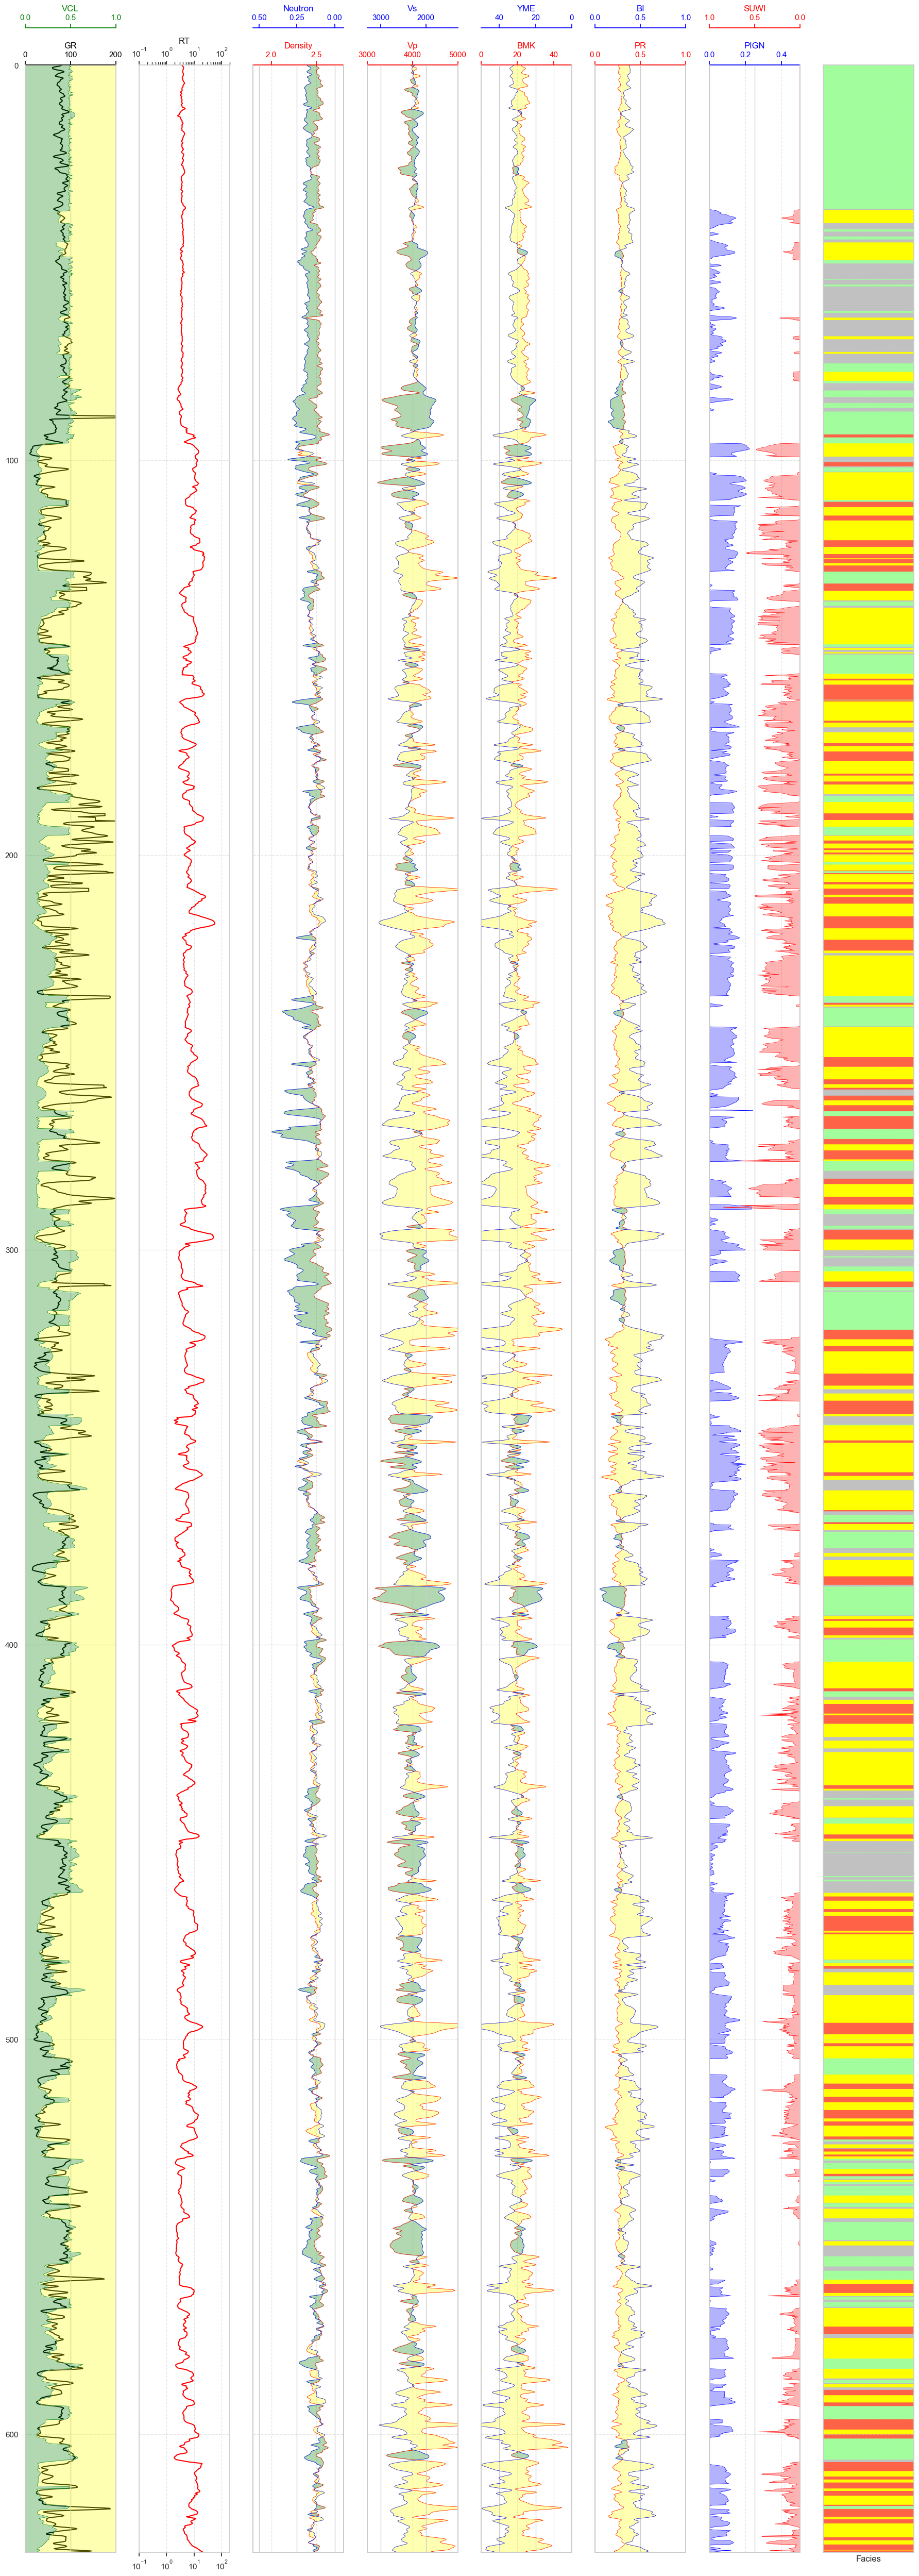

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

def plot_elastic_multitrack(df, depth_col="DEPTH", gr_col="GR", facies_col="FACIES"):
    # --- Data Prep ---
    facies_categories = ['Sandstone', 'Shale', 'Siltstone', 'Tight sandstone']
    lithology_numbers = {
        0: {'lith': 'Sandstone', 'hatch': '..', 'color': '#ffff00'},
        1: {'lith': 'Shale', 'hatch': '--', 'color': '#A2FD9D'},
        2: {'lith': 'Siltstone', 'hatch': 'xx', 'color': '#c1c1c1'},
        3: {'lith': 'Tight Sandstone', 'hatch': '///', 'color': '#ff6347'}
    }
    
    # Check if FACIES column exists
    has_facies = facies_col in df.columns
    
    if has_facies:
        # Process facies data
        df[facies_col] = df[facies_col].astype(str).str.lower()
        facies_mapping = {name.lower(): i for i, name in enumerate(facies_categories)}
        df['facies_code'] = df[facies_col].map(facies_mapping).fillna(-1).astype(int)

    cmap = mcolors.ListedColormap([lithology_numbers[i]['color'] for i in range(len(facies_categories))])
    
    depth = df[depth_col]
    
    # Determine number of subplots
    n_tracks = 8 if has_facies else 7
    fig, axes = plt.subplots(nrows=1, ncols=n_tracks, figsize=(18, 50), sharey=True)
    
    # --- Common Formatting ---
    for ax in axes:
        ax.set_ylim(depth.max(), depth.min())
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.tick_params(axis='x', top=True, bottom=True, labeltop=True, labelbottom=True)

    def enable_twin_ticks(ax):
        ax.tick_params(axis='x', top=True, bottom=True, labeltop=True, labelbottom=True)
        ax.spines["top"].set_position(("axes", 1.0))

    # --- Tracks 2 & 4 (Cross-over fills) ---
    def add_crossover(ax, ax_twin, col1, col2, color_pos, color_neg):
        x1 = df[col1]
        x2 = df[col2]
        # Normalize to common plot space
        ax_lim = ax.get_xlim()
        twin_lim = ax_twin.get_xlim()
        
        # Scaling logic for crossover
        x2_norm = ((x2 - twin_lim[0]) / (twin_lim[1] - twin_lim[0])) * (ax_lim[1] - ax_lim[0]) + ax_lim[0]
        ax.fill_betweenx(depth, x1, x2_norm, where=x1 >= x2_norm, color=color_pos, interpolate=True, alpha=0.3)
        ax.fill_betweenx(depth, x1, x2_norm, where=x1 <= x2_norm, color=color_neg, interpolate=True, alpha=0.3)

    # Plot Track 1: GR / VCL
    axes[0].plot(df[gr_col], depth, color="black")
    axes[0].set_xlim(0, 200)
    axes[0].set_xlabel("GR")
    axes[0].xaxis.label.set_color("black")
    axes[0].tick_params(axis='x', colors="black")
    axes[0].spines["top"].set_edgecolor("black")
    ax1 = axes[0].twiny()

    ax1.plot(df["VCL"], depth, color='green', lw=0.5)
    ax1.set_xlim(0, 1)
    ax1.set_xlabel('VCL')
    ax1.xaxis.label.set_color("green")
    ax1.spines["top"].set_position(("axes", 1.015))
    ax1.tick_params(axis='x', colors="green")
    ax1.spines["top"].set_edgecolor("green")
    ax1.fill_betweenx(df['DEPTH'], df['VCL'], 0, facecolor='green', alpha=0.3)
    ax1.fill_betweenx(df['DEPTH'], df['VCL'], 1, facecolor='yellow', alpha=0.3)
    for ax in [axes[0], ax1]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")
    
    # Track 2: RT
    axes[1].semilogx(df["RT"], depth, color="red")
    axes[1].set_xlim(0.1, 200)
    axes[1].set_xlabel("RT")
    axes[1].xaxis.set_ticks_position("top")
    axes[1].xaxis.set_label_position("top")
    axes[1].tick_params(axis='x', top=True, bottom=True, labeltop=True, labelbottom=True)
    
    # Track 3: RHOB/NPHI
    ax3 = axes[2].twiny()
    axes[2].plot(df["RHOB"], depth, color='red', lw=0.5)
    axes[2].set_xlim(1.8, 2.8)
    axes[2].set_xlabel('Density')
    axes[2].xaxis.label.set_color("red")
    axes[2].tick_params(axis='x', colors="red")
    axes[2].spines["top"].set_edgecolor("red")
    ax3.plot(df["NPHI"], depth, color='blue', lw=0.5)
    ax3.set_xlim(0.54, -0.06)
    ax3.set_xlabel('Neutron')
    ax3.xaxis.label.set_color("blue")
    ax3.spines["top"].set_position(("axes", 1.015))
    ax3.tick_params(axis='x', colors="blue")
    ax3.spines["top"].set_edgecolor("blue")
    add_crossover(axes[2], ax3, "RHOB", "NPHI", "green", "yellow")
    for ax in [axes[2], ax3]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")
    
    # Track 4: Vp/Vs
    ax4 = axes[3].twiny()
    axes[3].plot(df["Vp"], depth, color='red', lw=0.5)
    axes[3].set_xlim(3000, 5000)
    axes[3].set_xlabel('Vp')
    axes[3].xaxis.label.set_color("red")
    axes[3].tick_params(axis='x', colors="red")
    axes[3].spines["top"].set_edgecolor("red")
    ax4.plot(df["Vs"], depth, color='blue', lw=0.5)
    ax4.set_xlim(3300, 1300)
    ax4.set_xlabel('Vs')
    ax4.xaxis.label.set_color("blue")
    ax4.spines["top"].set_position(("axes", 1.015))
    ax4.tick_params(axis='x', colors="blue")
    ax4.spines["top"].set_edgecolor("blue")
    add_crossover(axes[3], ax4, "Vp", "Vs", "yellow", "green")
    for ax in [axes[3], ax4]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")
    
    # Track 5: Young's Modulus and BMK
    ax5 = axes[4].twiny()
    axes[4].plot(df["BMK"], depth, color='red', lw=0.5)
    axes[4].set_xlim(0, 50)
    axes[4].set_xlabel('BMK')
    axes[4].xaxis.label.set_color("red")
    axes[4].tick_params(axis='x', colors="red")
    axes[4].spines["top"].set_edgecolor("red")
    ax5.plot(df["YME"], depth, color='blue', lw=0.5)
    ax5.set_xlim(50, 0)
    ax5.set_xlabel('YME')
    ax5.xaxis.label.set_color("blue")
    ax5.spines["top"].set_position(("axes", 1.015))
    ax5.tick_params(axis='x', colors="blue")
    ax5.spines["top"].set_edgecolor("blue")
    add_crossover(axes[4], ax5, "BMK", "YME", "yellow", "green")
    for ax in [axes[4], ax5]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")
    
    # Track 6: PR and BI
    ax6 = axes[5].twiny()
    axes[5].plot(df["PR"], depth, color='red', lw=0.5)
    axes[5].set_xlim(0, 1)
    axes[5].set_xlabel('PR')
    axes[5].xaxis.label.set_color("red")
    axes[5].tick_params(axis='x', colors="red")
    axes[5].spines["top"].set_edgecolor("red")
    ax6.plot(df["BI"], depth, color='blue', lw=0.5)
    ax6.set_xlim(0, 1)
    ax6.set_xlabel('BI')
    ax6.xaxis.label.set_color("blue")
    ax6.spines["top"].set_position(("axes", 1.015))
    ax6.tick_params(axis='x', colors="blue")
    ax6.spines["top"].set_edgecolor("blue")
    add_crossover(axes[5], ax6, "PR", "BI", "green", "yellow")
    for ax in [axes[5], ax6]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")
    
    # Track 7: PIGN Sw
    ax7 = axes[6].twiny()
    axes[6].plot(df["PIGN"], depth, color='blue', lw=0.5)
    axes[6].set_xlim(0, 0.5)
    axes[6].set_xlabel('PIGN')
    axes[6].xaxis.label.set_color("blue")
    axes[6].tick_params(axis='x', colors="blue")
    axes[6].spines["top"].set_edgecolor("blue")
    ax7.plot((df["SUWI"]), depth, color='red', lw=0.5)
    ax7.set_xlim(1, 0)
    ax7.set_xlabel('SUWI')
    ax7.xaxis.label.set_color("red")
    ax7.spines["top"].set_position(("axes", 1.015))
    ax7.tick_params(axis='x', colors="red")
    ax7.spines["top"].set_edgecolor("red")
    axes[6].fill_betweenx(df['DEPTH'], df['PIGN'], 0, facecolor='blue', alpha=0.3)
    ax7.fill_betweenx(df['DEPTH'], (df['SUWI']), 0, facecolor='red', alpha=0.3)
    for ax in [axes[6], ax7]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")
    
    # Plot Facies if exists
    if has_facies:
        ax8 = axes[7]
        facies_codes = df['facies_code'].values.reshape(-1, 1)
        extent = [0, 1, depth.max(), depth.min()]
        ax8.imshow(facies_codes, aspect='auto', cmap=cmap, extent=extent, origin='upper')
        ax8.set_xlabel("Facies")
        ax8.set_xticks([])
    else:
        # If no facies column, do not plot the 8th track
        pass
    
    plt.tight_layout()
    plt.savefig(f"{WELL_1}_LogPlot.pdf")
    plt.savefig(f"{WELL_1}_LogPlot.png")
    plt.show()

# Call your function with your DataFrame
plot_elastic_multitrack(df)

In [16]:
# ---------------------------------------------------------
# 7. Save final output
# ---------------------------------------------------------
#output_file = "{WELL_1}_processed.csv"
# Round the entire dataframe to 3 decimal places for display
df_rounded = df.round(3)
df_rounded.to_csv(f"{WELL_1}_processed.csv", index=False)

print(f"Processed file saved as: {WELL_1}_processed.csv")


Processed file saved as: Well-C_processed.csv
